# Exploratory Data Analysis — European Soccer Database

## Objectives

1. Explore the seven original relational tables.
2. Understand match outcomes, teams, leagues and players.
3. Investigate missing values, duplicates and outliers.
4. Analyze the engineered machine learning features.
5. Identify data-cleaning and preprocessing requirements.
6. Save important figures and summary tables for reporting.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project directory
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Data folders
RAW_DIR = PROJECT_ROOT / "data" / "extracted"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Output folders
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# Plot settings
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("Project root:", PROJECT_ROOT)
print("Figures folder:", FIGURES_DIR)
print("Tables folder:", TABLES_DIR)

141.68s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


141.68s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.
Project root: /Users/sasanda/Documents/GitHub/european-soccer-machine-learning
Figures folder: /Users/sasanda/Documents/GitHub/european-soccer-machine-learning/outputs/figures
Tables folder: /Users/sasanda/Documents/GitHub/european-soccer-machine-learning/outputs/tables


In [6]:
model_df = pd.read_csv(
    PROCESSED_DIR / "model_data_engineered.csv",
    parse_dates=["date"]
)

print("Dataset shape:", model_df.shape)
display(model_df.head())

Dataset shape: (17609, 156)


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,recent_goals_scored_diff,recent_goals_conceded_diff,buildUpPlaySpeed_diff,buildUpPlayPassing_diff,chanceCreationPassing_diff,chanceCreationCrossing_diff,chanceCreationShooting_diff,defencePressure_diff,defenceAggression_diff,defenceTeamWidth_diff
0,24918,24558,24558,2010/2011,1,2010-07-17,845024,9956,7955,1,...,0.6,-2.0,-30.0,5.0,-5.0,0.0,-5.0,-10.0,15.0,5.0
1,24920,24558,24558,2010/2011,1,2010-07-18,845026,6493,10179,0,...,-0.6,-0.2,5.0,-10.0,5.0,5.0,-5.0,10.0,10.0,10.0
2,24921,24558,24558,2010/2011,1,2010-07-18,845027,10199,10190,4,...,1.8,-2.0,10.0,0.0,10.0,15.0,5.0,-10.0,-10.0,0.0
3,24922,24558,24558,2010/2011,1,2010-07-20,845028,9931,10243,3,...,1.2,-1.8,-5.0,-15.0,5.0,-5.0,0.0,10.0,5.0,10.0
4,24973,24558,24558,2010/2011,2,2010-07-24,845029,10179,9931,1,...,-1.2,1.0,-5.0,15.0,0.0,-5.0,10.0,-25.0,-20.0,-15.0


### 1. Match Table — Exploratory Data Analysis

The Match table contains historical football matches,
including participating teams, leagues, match dates,
and final scores.

Objectives:
- Understand the structure of match records.
- Identify missing values and duplicates.
- Analyze match outcomes and goal distributions.
- Investigate home advantage.
- Detect potential data quality issues.

In [11]:
match_df = pd.read_csv("../data/extracted/Match.csv")

match_df.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67


In [12]:
match_df.shape

(25979, 115)

In [13]:
match_df.columns

Index(['id', 'country_id', 'league_id', 'season', 'stage', 'date',
       'match_api_id', 'home_team_api_id', 'away_team_api_id',
       'home_team_goal',
       ...
       'SJA', 'VCH', 'VCD', 'VCA', 'GBH', 'GBD', 'GBA', 'BSH', 'BSD', 'BSA'],
      dtype='str', length=115)

In [14]:
match_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25979 entries, 0 to 25978
Columns: 115 entries, id to BSA
dtypes: float64(96), int64(9), str(10)
memory usage: 22.8 MB


In [ ]:
match_df.isnull().sum()

id                0
country_id        0
league_id         0
season            0
stage             0
              ...  
GBD           11817
GBA           11817
BSH           11818
BSD           11818
BSA           11818
Length: 115, dtype: int64


In [16]:
match_df["id"].duplicated().sum()

np.int64(0)

In [18]:
match_df.describe()

,id,country_id,league_id,stage,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,home_player_X1,...,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
count,25979.000000,25979.000000,25979.000000,25979.000000,2.597900e+04,25979.000000,25979.000000,25979.000000,25979.000000,24158.000000,...,17097.000000,22568.000000,22568.000000,22568.000000,14162.000000,14162.000000,14162.000000,14161.000000,14161.000000,14161.000000
mean,12990.000000,11738.630317,11738.630317,18.242773,1.195429e+06,9984.371993,9984.475115,1.544594,1.160938,0.999586,...,4.622343,2.668107,3.899048,4.840281,2.498764,3.648189,4.353097,2.497894,3.660742,4.405663
std,7499.635658,7553.936759,7553.936759,10.407354,4.946279e+05,14087.453758,14087.445135,1.297158,1.142110,0.022284,...,3.632164,1.928753,1.248221,4.318338,1.489299,0.867440,3.010189,1.507793,0.868272,3.189814
min,1.000000,1.000000,1.000000,1.000000,4.831290e+05,1601.000000,1601.000000,0.000000,0.000000,0.000000,...,1.100000,1.030000,1.620000,1.080000,1.050000,1.450000,1.120000,1.040000,1.330000,1.120000
25%,6495.500000,4769.000000,4769.000000,9.000000,7.684365e+05,8475.000000,8475.000000,1.000000,0.000000,1.000000,...,2.500000,1.700000,3.300000,2.550000,1.670000,3.200000,2.500000,1.670000,3.250000,2.500000
50%,12990.000000,10257.000000,10257.000000,18.000000,1.147511e+06,8697.000000,8697.000000,1.000000,1.000000,1.000000,...,3.500000,2.150000,3.500000,3.500000,2.100000,3.300000,3.400000,2.100000,3.400000,3.400000
75%,19484.500000,17642.000000,17642.000000,27.000000,1.709852e+06,9925.000000,9925.000000,2.000000,2.000000,1.000000,...,5.250000,2.800000,4.000000,5.400000,2.650000,3.750000,5.000000,2.620000,3.750000,5.000000
max,25979.000000,24558.000000,24558.000000,38.000000,2.216672e+06,274581.000000,274581.000000,10.000000,9.000000,2.000000,...,41.000000,36.000000,26.000000,67.000000,21.000000,11.000000,34.000000,17.000000,13.000000,34.000000


In [19]:
missing = match_df.isnull().sum()

missing.to_csv("../outputs/tables/match_missing_values.csv")

In [20]:
match_df["result"] = "Draw"

match_df.loc[
    match_df["home_team_goal"] > match_df["away_team_goal"],
    "result"
] = "Home Win"

match_df.loc[
    match_df["home_team_goal"] < match_df["away_team_goal"],
    "result"
] = "Away Win"

/var/folders/_6/kwx5pdg56rq735gq7lswf8hm0000gn/T/ipykernel_96246/619417100.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  match_df["result"] = "Draw"


In [21]:
match_df["result"].value_counts()

result
Home Win    11917
Away Win     7466
Draw         6596
Name: count, dtype: int64

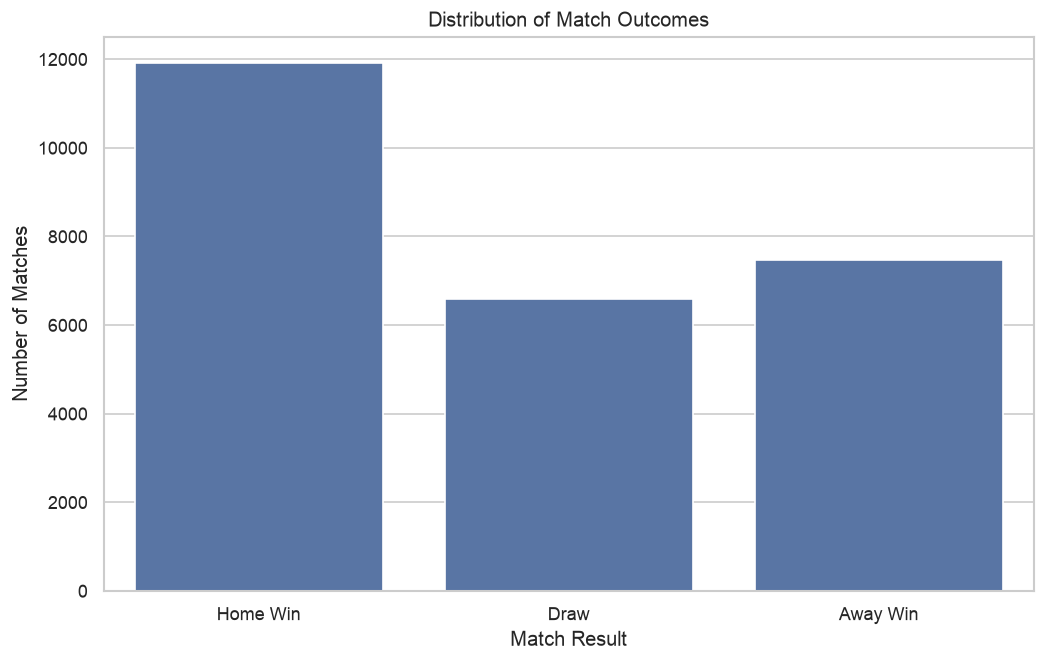

In [ ]:
sns.countplot(
    data=match_df,
    x="result",
    order=["Home Win", "Draw", "Away Win"]
)

plt.title("Distribution of Match Outcomes")
plt.xlabel("Match Result")
plt.ylabel("Number of Matches")

plt.show()

In [23]:
match_df[["home_team_goal", "away_team_goal"]].describe()

,home_team_goal,away_team_goal
count,25979.000000,25979.000000
mean,1.544594,1.160938
std,1.297158,1.142110
min,0.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,1.000000
75%,2.000000,2.000000
max,10.000000,9.000000


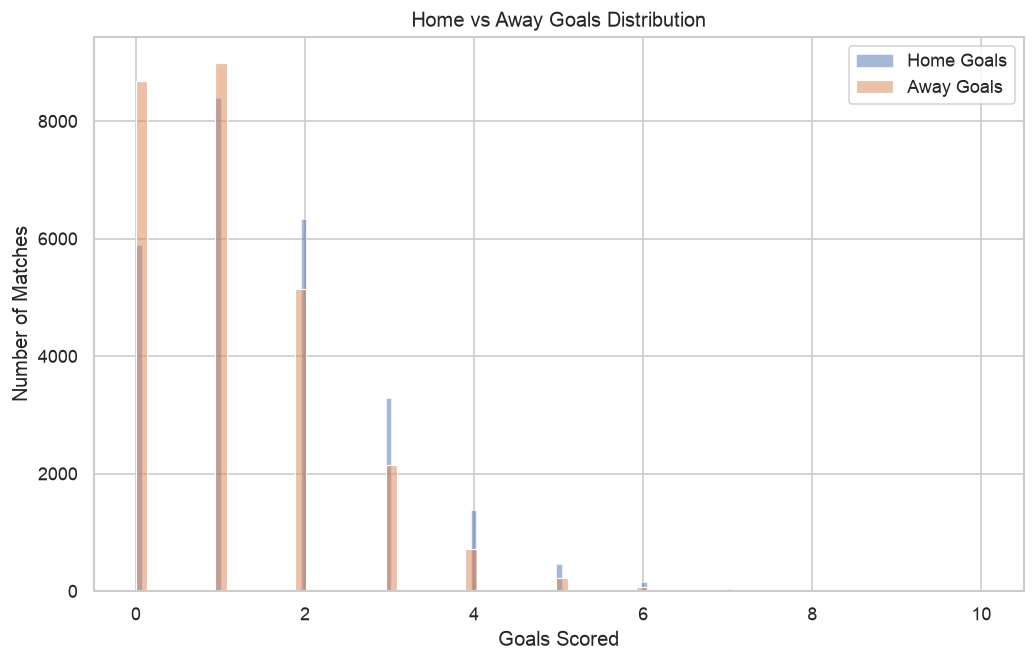

In [ ]:
sns.histplot(match_df["home_team_goal"], label="Home Goals", alpha=0.5)
sns.histplot(match_df["away_team_goal"], label="Away Goals", alpha=0.5)

plt.legend()
plt.title("Home vs Away Goals Distribution")
plt.xlabel("Goals Scored")
plt.ylabel("Number of Matches")

plt.show()

In [25]:
print("Average home goals:", match_df["home_team_goal"].mean())
print("Average away goals:", match_df["away_team_goal"].mean())

Average home goals: 1.5445937103044767
Average away goals: 1.1609376804341969


In [26]:
match_df["total_goals"] = (
    match_df["home_team_goal"] + match_df["away_team_goal"]
)

match_df["total_goals"].describe()

/var/folders/_6/kwx5pdg56rq735gq7lswf8hm0000gn/T/ipykernel_96246/2115342366.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  match_df["total_goals"] = (


count    25979.000000
mean         2.705531
std          1.672456
min          0.000000
25%          2.000000
50%          3.000000
75%          4.000000
max         12.000000
Name: total_goals, dtype: float64

### League-wise match analysis

In [27]:
league_df = pd.read_csv("../data/extracted/League.csv")

league_df.head()

,id,country_id,name
0,1,1,Belgium Jupiler League
1,1729,1729,England Premier League
2,4769,4769,France Ligue 1
3,7809,7809,Germany 1. Bundesliga
4,10257,10257,Italy Serie A


In [28]:
match_league = match_df.merge(
    league_df[["id", "name"]],
    left_on="league_id",
    right_on="id",
    how="left"
)

match_league.head()

,id_x,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,GBH,GBD,GBA,BSH,BSD,BSA,result,total_goals,id_y,name
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,1.78,3.25,4.00,1.73,3.40,4.20,Draw,2,1,Belgium Jupiler League
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,1.85,3.25,3.75,1.91,3.25,3.60,Draw,0,1,Belgium Jupiler League
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,2.50,3.20,2.50,2.30,3.20,2.75,Away Win,3,1,Belgium Jupiler League
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,1.50,3.75,5.50,1.44,3.75,6.50,Home Win,5,1,Belgium Jupiler League
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,4.50,3.50,1.65,4.75,3.30,1.67,Away Win,4,1,Belgium Jupiler League


In [29]:
match_league["name"].value_counts()

name
England Premier League      3040
France Ligue 1              3040
Spain LIGA BBVA             3040
Italy Serie A               3017
Germany 1. Bundesliga       2448
Netherlands Eredivisie      2448
Portugal Liga ZON Sagres    2052
Poland Ekstraklasa          1920
Scotland Premier League     1824
Belgium Jupiler League      1728
Switzerland Super League    1422
Name: count, dtype: int64

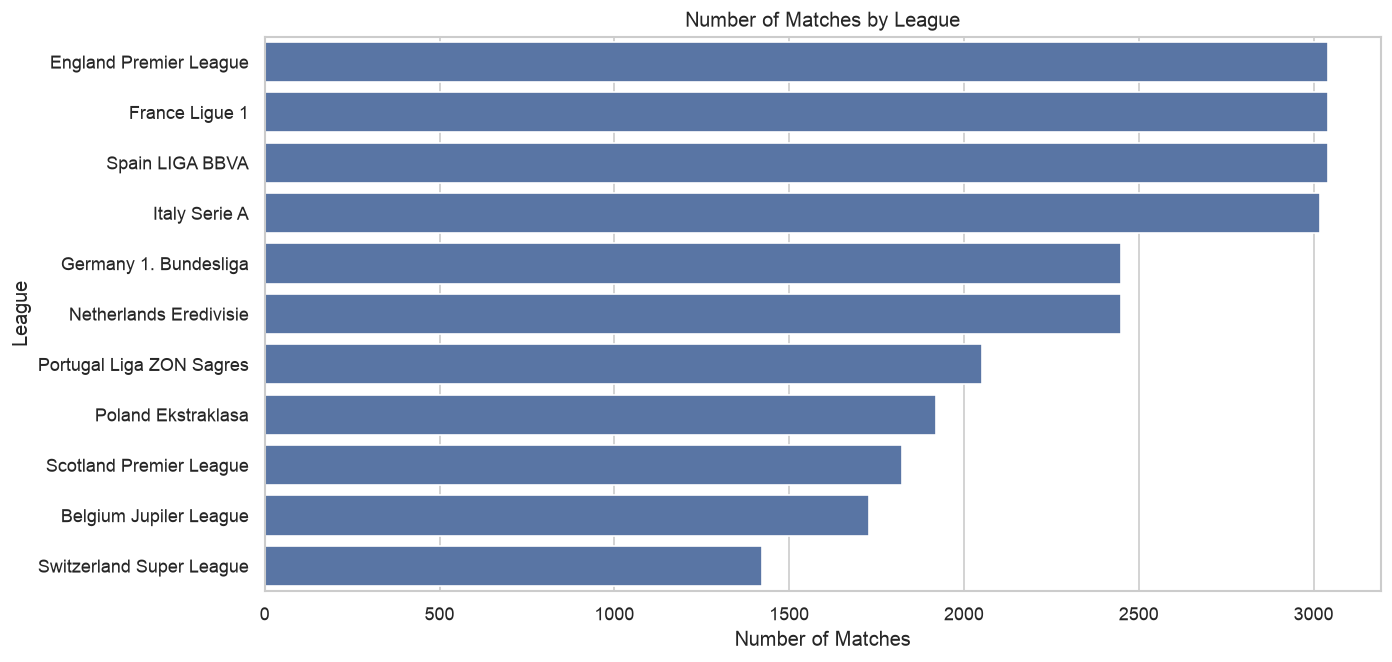

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=match_league,
    y="name",
    order=match_league["name"].value_counts().index
)

plt.title("Number of Matches by League")
plt.xlabel("Number of Matches")
plt.ylabel("League")


plt.show()

In [31]:
match_league["home_win"] = (
    match_league["result"] == "Home Win"
)

home_win_rate = (
    match_league.groupby("name")["home_win"].mean() * 100
)

home_win_rate = home_win_rate.sort_values(ascending=False)

home_win_rate

/var/folders/_6/kwx5pdg56rq735gq7lswf8hm0000gn/T/ipykernel_96246/882388460.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  match_league["home_win"] = (


name
Spain LIGA BBVA             48.848684
Netherlands Eredivisie      47.834967
Belgium Jupiler League      46.875000
Italy Serie A               46.635731
England Premier League      45.723684
Switzerland Super League    45.710267
Poland Ekstraklasa          45.312500
Germany 1. Bundesliga       45.220588
France Ligue 1              44.703947
Portugal Liga ZON Sagres    44.249513
Scotland Premier League     41.666667
Name: home_win, dtype: float64

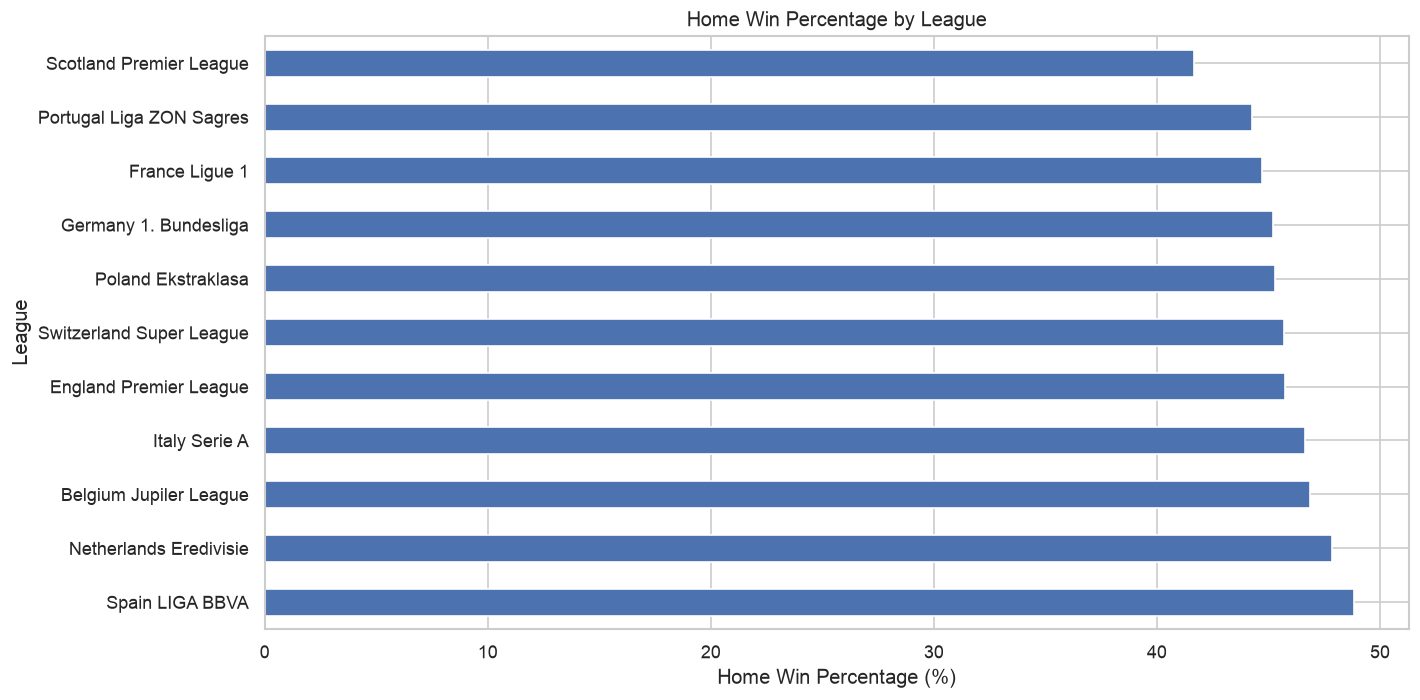

In [ ]:
plt.figure(figsize=(12, 6))

home_win_rate.plot(kind="barh")

plt.title("Home Win Percentage by League")
plt.xlabel("Home Win Percentage (%)")
plt.ylabel("League")

plt.tight_layout()


plt.show()

In [33]:
avg_goals = (
    match_league.groupby("name")["total_goals"]
    .mean()
    .sort_values(ascending=False)
)

avg_goals

name
Netherlands Eredivisie      3.080882
Switzerland Super League    2.929677
Germany 1. Bundesliga       2.901552
Belgium Jupiler League      2.801505
Spain LIGA BBVA             2.767105
England Premier League      2.710526
Scotland Premier League     2.633772
Italy Serie A               2.616838
Portugal Liga ZON Sagres    2.534600
France Ligue 1              2.443092
Poland Ekstraklasa          2.425000
Name: total_goals, dtype: float64

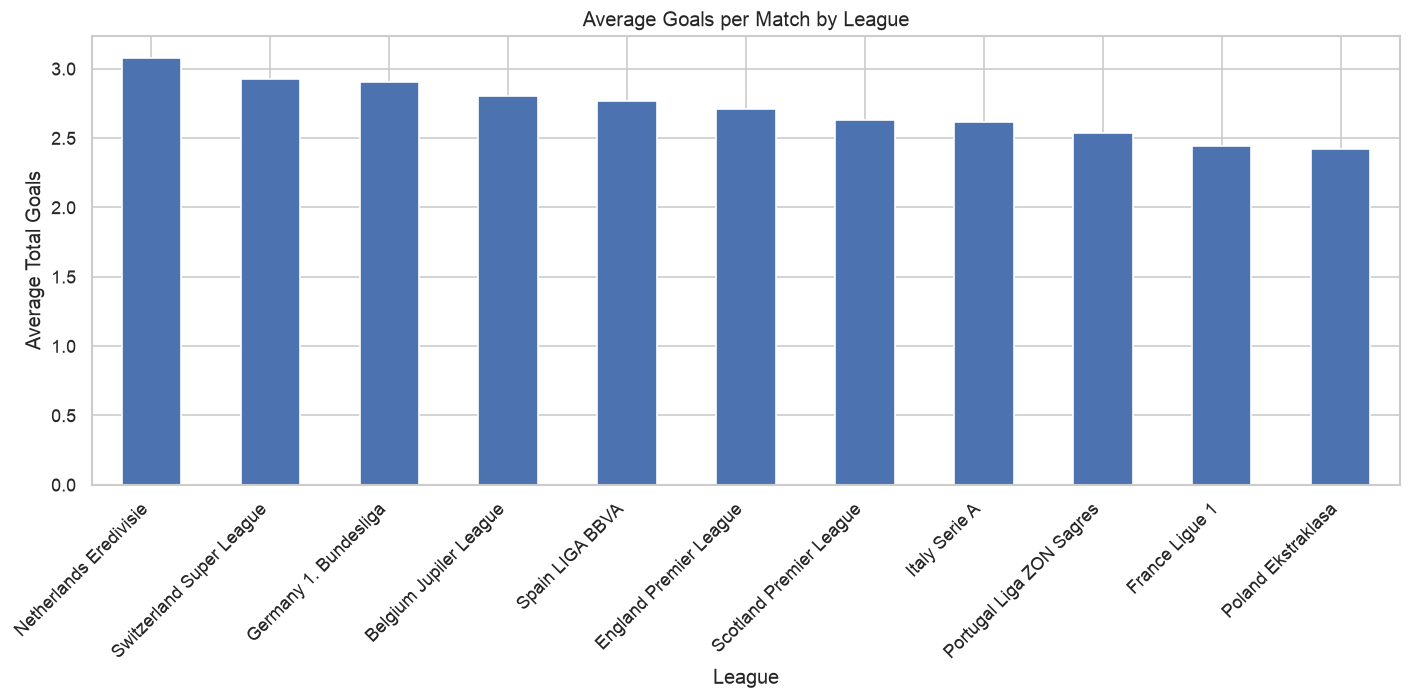

In [ ]:
plt.figure(figsize=(12, 6))

avg_goals.plot(kind="bar")

plt.title("Average Goals per Match by League")
plt.xlabel("League")
plt.ylabel("Average Total Goals")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()


plt.show()

In [35]:
league_summary = pd.DataFrame({
    "matches": match_league.groupby("name").size(),
    "home_win_percentage": home_win_rate,
    "average_goals": avg_goals
})

league_summary.to_csv("../outputs/tables/league_summary.csv")

league_summary

,matches,home_win_percentage,average_goals
name,,,
Belgium Jupiler League,1728,46.875000,2.801505
England Premier League,3040,45.723684,2.710526
France Ligue 1,3040,44.703947,2.443092
Germany 1. Bundesliga,2448,45.220588,2.901552
Italy Serie A,3017,46.635731,2.616838
Netherlands Eredivisie,2448,47.834967,3.080882
Poland Ekstraklasa,1920,45.312500,2.425000
Portugal Liga ZON Sagres,2052,44.249513,2.534600
Scotland Premier League,1824,41.666667,2.633772


In [36]:
match_df["season"].value_counts().sort_index()

season
2008/2009    3326
2009/2010    3230
2010/2011    3260
2011/2012    3220
2012/2013    3260
2013/2014    3032
2014/2015    3325
2015/2016    3326
Name: count, dtype: int64

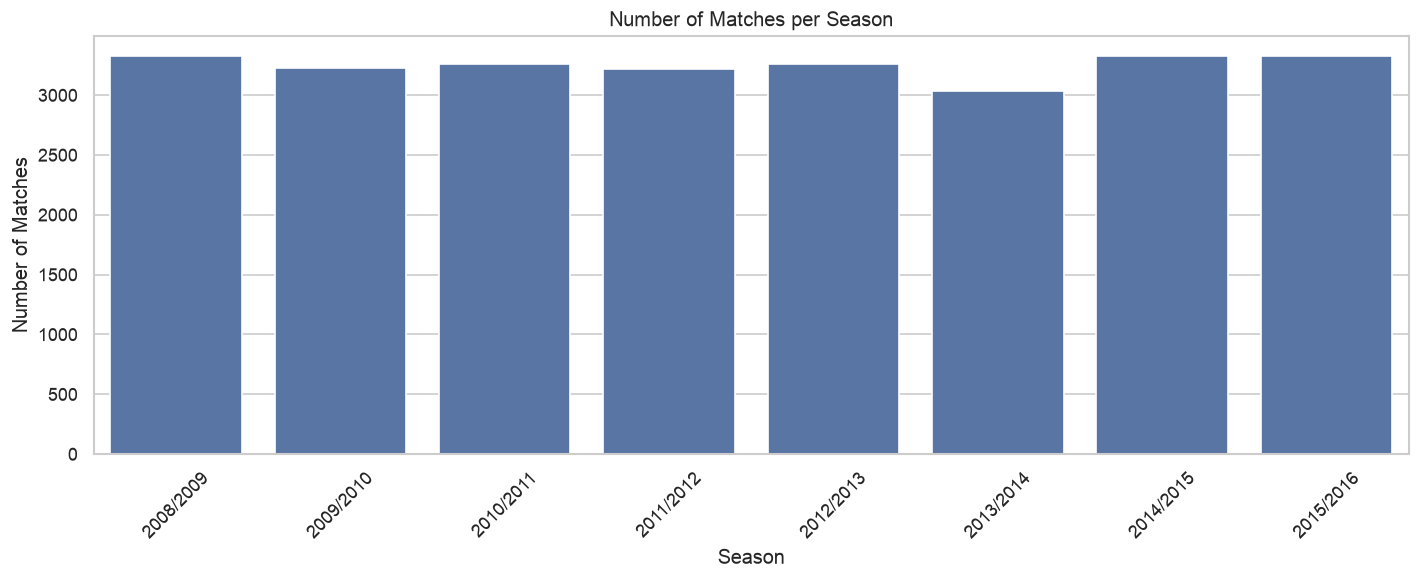

In [ ]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=match_df,
    x="season",
    order=sorted(match_df["season"].dropna().unique())
)

plt.title("Number of Matches per Season")
plt.xlabel("Season")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [38]:
season_goals = match_df.groupby("season")["total_goals"].mean()

season_goals


season
2008/2009    2.607336
2009/2010    2.672446
2010/2011    2.683742
2011/2012    2.716460
2012/2013    2.772699
2013/2014    2.766821
2014/2015    2.675789
2015/2016    2.754660
Name: total_goals, dtype: float64

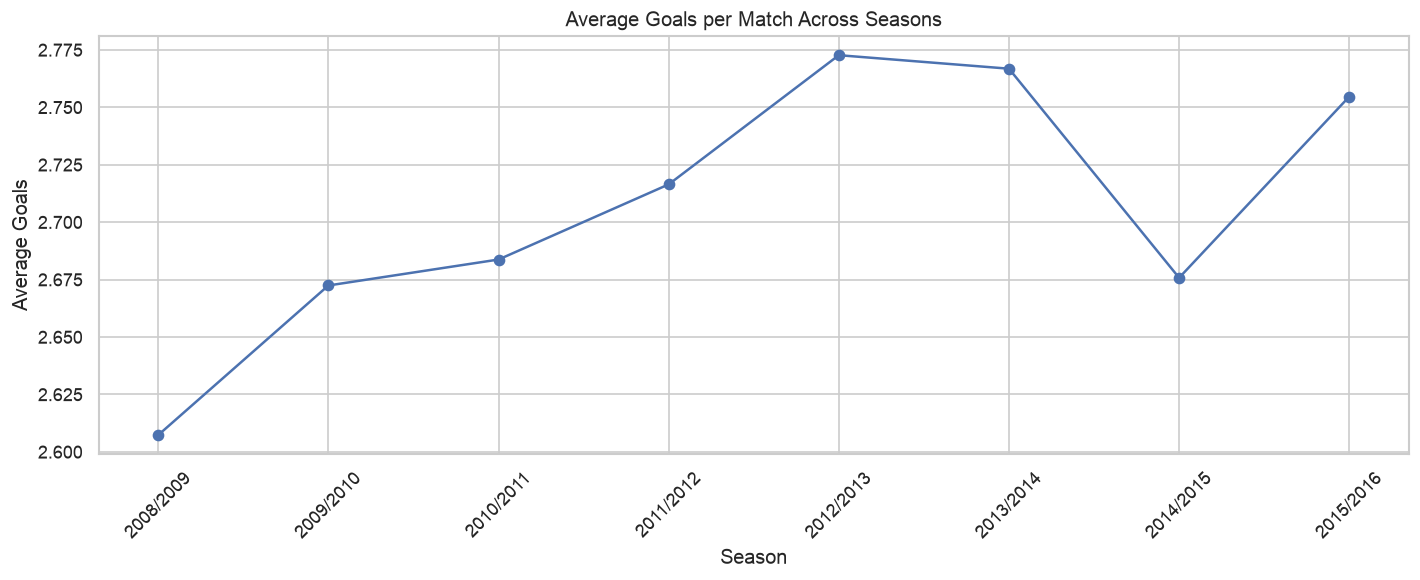

In [ ]:
plt.figure(figsize=(12, 5))

season_goals.plot(kind="line", marker="o")

plt.title("Average Goals per Match Across Seasons")
plt.xlabel("Season")
plt.ylabel("Average Goals")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [40]:
match_df["home_win"] = match_df["result"] == "Home Win"

season_home_wins = (
    match_df.groupby("season")["home_win"].mean() * 100
)

season_home_wins

/var/folders/_6/kwx5pdg56rq735gq7lswf8hm0000gn/T/ipykernel_96246/3690768469.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  match_df["home_win"] = match_df["result"] == "Home Win"


season
2008/2009    47.083584
2009/2010    47.430341
2010/2011    46.625767
2011/2012    46.521739
2012/2013    44.294479
2013/2014    46.306069
2014/2015    44.932331
2015/2016    43.866506
Name: home_win, dtype: float64

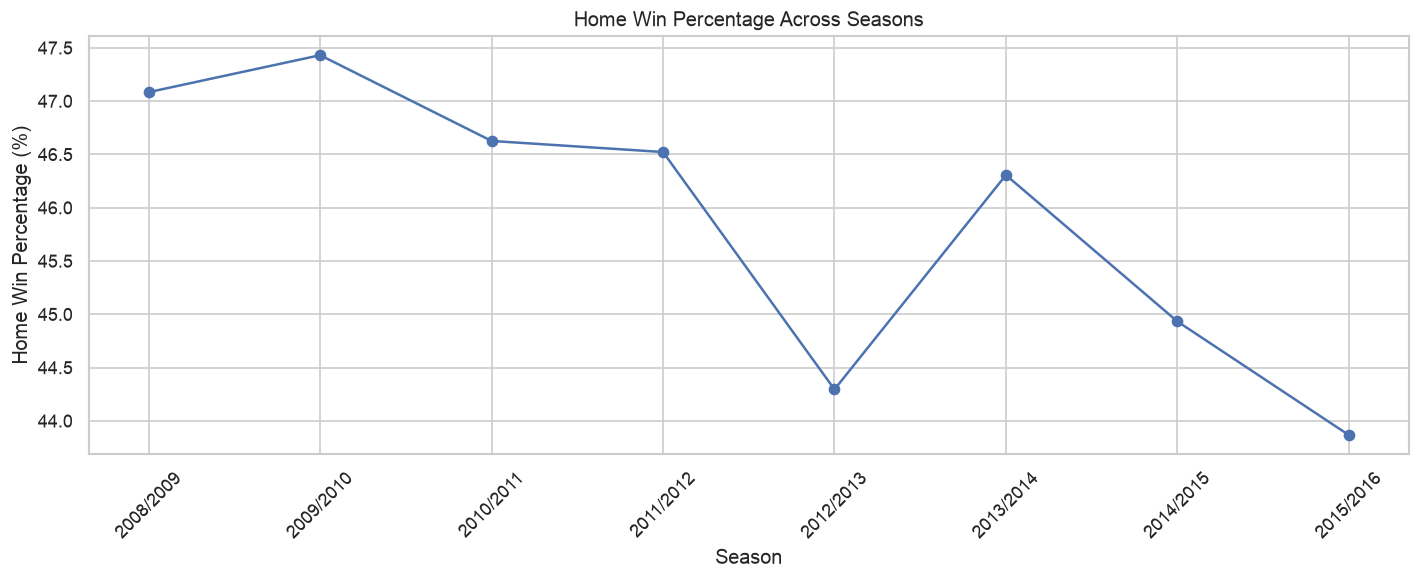

In [ ]:
plt.figure(figsize=(12, 5))

season_home_wins.plot(kind="line", marker="o")

plt.title("Home Win Percentage Across Seasons")
plt.xlabel("Season")
plt.ylabel("Home Win Percentage (%)")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [42]:
season_results = pd.crosstab(
    match_df["season"],
    match_df["result"],
    normalize="index"
) * 100

season_results

result,Away Win,Draw,Home Win
season,,,
2008/2009,27.931449,24.984967,47.083584
2009/2010,27.368421,25.201238,47.430341
2010/2011,27.638037,25.736196,46.625767
2011/2012,28.074534,25.403727,46.521739
2012/2013,29.539877,26.165644,44.294479
2013/2014,29.419525,24.274406,46.306069
2014/2015,29.503759,25.563910,44.932331
2015/2016,30.426939,25.706554,43.866506


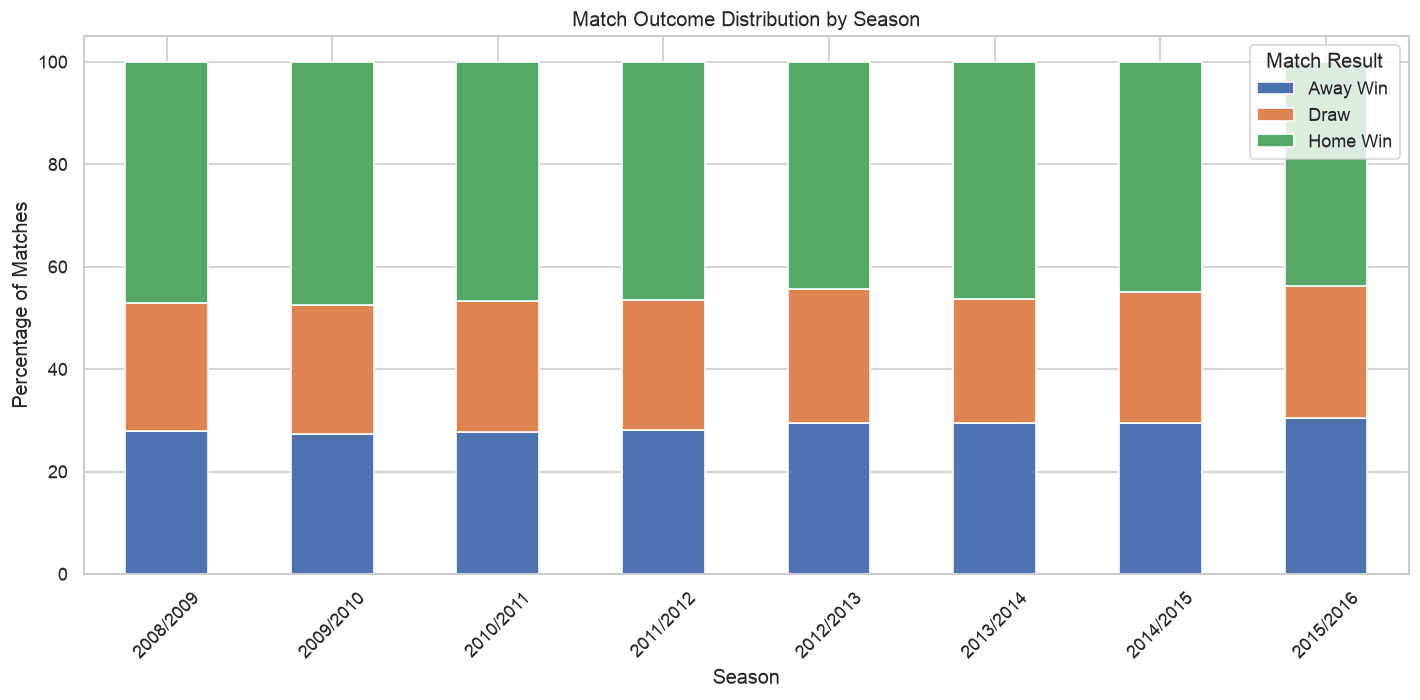

In [ ]:
season_results.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Match Outcome Distribution by Season")
plt.xlabel("Season")
plt.ylabel("Percentage of Matches")
plt.legend(title="Match Result")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [44]:
season_summary = pd.DataFrame({
    "match_count": match_df.groupby("season").size(),
    "average_goals": season_goals,
    "home_win_percentage": season_home_wins
})

season_summary.to_csv("../outputs/tables/season_summary.csv")

season_summary

,match_count,average_goals,home_win_percentage
season,,,
2008/2009,3326,2.607336,47.083584
2009/2010,3230,2.672446,47.430341
2010/2011,3260,2.683742,46.625767
2011/2012,3220,2.716460,46.521739
2012/2013,3260,2.772699,44.294479
2013/2014,3032,2.766821,46.306069
2014/2015,3325,2.675789,44.932331
2015/2016,3326,2.754660,43.866506


In [45]:
important_columns = [
    "id",
    "date",
    "season",
    "league_id",
    "home_team_api_id",
    "away_team_api_id",
    "home_team_goal",
    "away_team_goal"
]

match_df[important_columns].isnull().sum()

id                  0
date                0
season              0
league_id           0
home_team_api_id    0
away_team_api_id    0
home_team_goal      0
away_team_goal      0
dtype: int64

In [46]:
match_df["id"].duplicated().sum()

np.int64(0)

In [47]:
same_team = match_df[
    match_df["home_team_api_id"] == match_df["away_team_api_id"]
]

same_team.shape

(0, 118)

In [48]:
match_df[["home_team_goal", "away_team_goal"]].describe()

,home_team_goal,away_team_goal
count,25979.000000,25979.000000
mean,1.544594,1.160938
std,1.297158,1.142110
min,0.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,1.000000
75%,2.000000,2.000000
max,10.000000,9.000000


In [49]:
match_df.sort_values(
    "home_team_goal",
    ascending=False
)[["date", "home_team_goal", "away_team_goal"]].head(10)

,date,home_team_goal,away_team_goal
24247,2015-12-20 00:00:00,10,2
13898,2010-10-24 00:00:00,10,0
24015,2015-04-05 00:00:00,9,1
2156,2009-11-22 00:00:00,9,1
9210,2013-03-30 00:00:00,9,2
20161,2010-11-06 00:00:00,9,0
4375,2014-10-18 00:00:00,8,0
3338,2012-12-23 00:00:00,8,0
22587,2011-05-21 00:00:00,8,1
21337,2016-01-19 00:00:00,8,1


In [50]:
match_df.sort_values(
    "away_team_goal",
    ascending=False
)[["date", "home_team_goal", "away_team_goal"]].head(10)

,date,home_team_goal,away_team_goal
7660,2016-03-13 00:00:00,0,9
22310,2010-11-20 00:00:00,0,8
24450,2016-04-20 00:00:00,0,8
8662,2011-05-07 00:00:00,1,8
24122,2014-09-20 00:00:00,2,8
24081,2015-05-02 00:00:00,0,8
24736,2008-09-14 00:00:00,1,7
11214,2011-02-27 00:00:00,0,7
25901,2016-04-17 00:00:00,0,7
24765,2009-10-29 00:00:00,1,7


In [51]:
match_df[
    (match_df["home_team_goal"] < 0) |
    (match_df["away_team_goal"] < 0)
]

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,VCA,GBH,GBD,GBA,BSH,BSD,BSA,result,total_goals,home_win


In [52]:
match_df["date"] = pd.to_datetime(match_df["date"])

In [53]:
print("First match:", match_df["date"].min())
print("Last match:", match_df["date"].max())

First match: 2008-07-18 00:00:00
Last match: 2016-05-25 00:00:00


In [54]:
match_df["year"] = match_df["date"].dt.year

match_df["year"].value_counts().sort_index()

/var/folders/_6/kwx5pdg56rq735gq7lswf8hm0000gn/T/ipykernel_96246/1558966068.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  match_df["year"] = match_df["date"].dt.year


year
2008    1613
2009    3306
2010    3250
2011    3255
2012    3269
2013    3116
2014    3166
2015    3374
2016    1630
Name: count, dtype: int64

In [55]:
match_quality = pd.DataFrame({
    "check": [
        "Total matches",
        "Duplicate match IDs",
        "Duplicate rows",
        "Missing home team IDs",
        "Missing away team IDs",
        "Missing home goals",
        "Missing away goals"
    ],

    "value": [
        len(match_df),
        match_df["id"].duplicated().sum(),
        match_df.duplicated().sum(),
        match_df["home_team_api_id"].isnull().sum(),
        match_df["away_team_api_id"].isnull().sum(),
        match_df["home_team_goal"].isnull().sum(),
        match_df["away_team_goal"].isnull().sum()
    ]
})

match_quality

,check,value
0,Total matches,25979
1,Duplicate match IDs,0
2,Duplicate rows,0
3,Missing home team IDs,0
4,Missing away team IDs,0
5,Missing home goals,0
6,Missing away goals,0


In [56]:
match_quality.to_csv(
    "../outputs/tables/match_data_quality.csv",
    index=False
)

### 2. Team Table — Exploratory Data Analysis

The Team table contains the football teams in the dataset.

The main purpose of this table is to connect team IDs in the Match table
with readable team names.

In [57]:
team_df = pd.read_csv("../data/extracted/Team.csv")

team_df.head()

,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
0,1,9987,673.0,KRC Genk,GEN
1,2,9993,675.0,Beerschot AC,BAC
2,3,10000,15005.0,SV Zulte-Waregem,ZUL
3,4,9994,2007.0,Sporting Lokeren,LOK
4,5,9984,1750.0,KSV Cercle Brugge,CEB


In [58]:
team_df.shape

(299, 5)

In [59]:
team_df.isnull().sum()

id                   0
team_api_id          0
team_fifa_api_id    11
team_long_name       0
team_short_name      0
dtype: int64

In [60]:
team_df["team_api_id"].duplicated().sum()

np.int64(0)

In [61]:
team_df["team_long_name"].duplicated().sum()

np.int64(3)

In [62]:
team_df[
    team_df["team_long_name"].duplicated(keep=False)
].sort_values("team_long_name")

,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
182,31444,8031,111429.0,Polonia Bytom,POB
183,31445,8020,111429.0,Polonia Bytom,GOR
15,16,9996,111560.0,Royal Excel Mouscron,MOU
24,2510,274581,111560.0,Royal Excel Mouscron,MOP
189,31451,8244,301.0,Widzew Łódź,LOD
199,32409,8024,301.0,Widzew Łódź,WID


In [63]:
team_df[
    team_df["team_fifa_api_id"].isnull()
][["team_api_id", "team_long_name"]]

,team_api_id,team_long_name
8,7947,FCV Dender EH
14,4049,Tubize
170,6601,FC Volendam
204,177361,Termalica Bruk-Bet Nieciecza
208,7992,Trofense
213,10213,Amadora
223,9765,Portimonense
225,4064,Feirense
232,6367,Uniao da Madeira
233,188163,Tondela


In [66]:
print(
    "Home team IDs found:",
    match_df["home_team_api_id"].isin(
        team_df["team_api_id"]
    ).mean() * 100
)

print(
    "Away team IDs found:",
    match_df["away_team_api_id"].isin(
        team_df["team_api_id"]
    ).mean() * 100
)

Home team IDs found: 100.0
Away team IDs found: 100.0


In [67]:
home_matches = match_df["home_team_api_id"].value_counts()

In [68]:
away_matches = match_df["away_team_api_id"].value_counts()

In [69]:
team_matches = home_matches.add(
    away_matches,
    fill_value=0
)

In [70]:
team_matches.sort_values(
    ascending=False
).head(10)

home_team_api_id
9825     304
8302     304
8558     304
9906     304
8592     304
8315     304
10194    304
8668     304
9925     304
8305     304
Name: count, dtype: int64

In [71]:
team_match_count = team_df[
    ["team_api_id", "team_long_name"]
].copy()

team_match_count["matches"] = (
    team_match_count["team_api_id"]
    .map(team_matches)
)

team_match_count.sort_values(
    "matches",
    ascending=False
).head(10)

,team_api_id,team_long_name,matches
61,9827,Girondins de Bordeaux,304
242,9925,Celtic,304
68,9941,Toulouse FC,304
240,8485,Aberdeen,304
67,9748,Olympique Lyonnais,304
238,8597,Kilmarnock,304
25,10260,Manchester United,304
66,8689,FC Lorient,304
27,9825,Arsenal,304
64,9831,OGC Nice,304


In [72]:
top_teams = team_match_count.sort_values(
    "matches",
    ascending=False
).head(10)

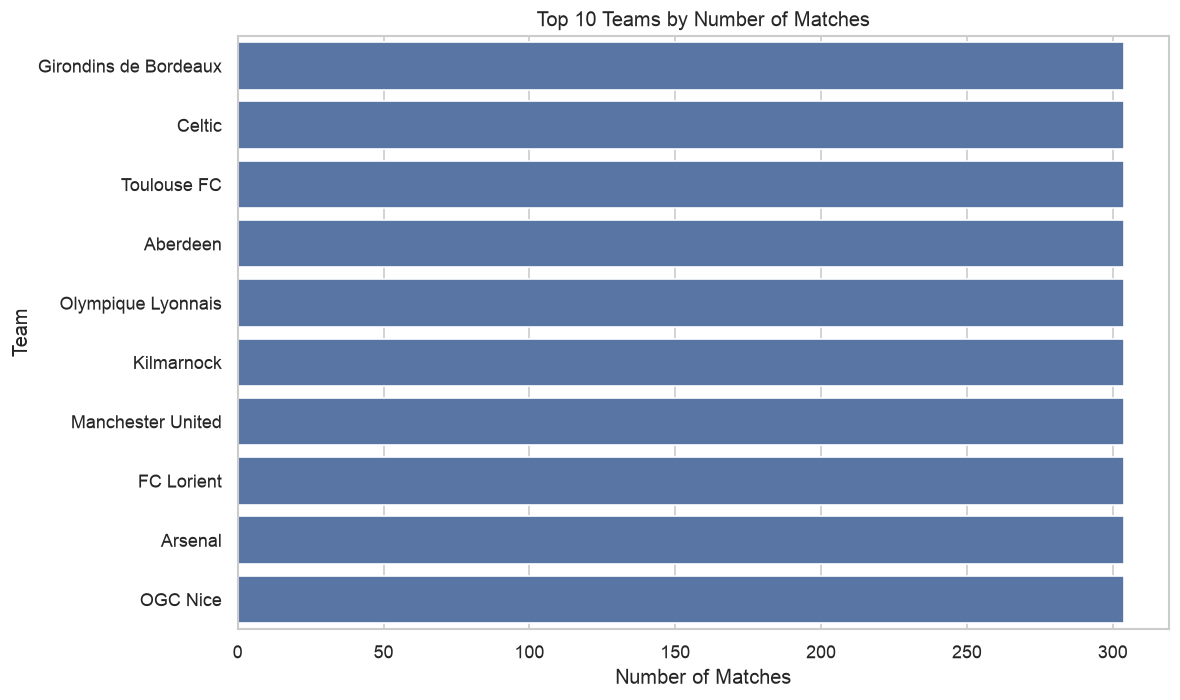

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_teams,
    x="matches",
    y="team_long_name"
)

plt.title("Top 10 Teams by Number of Matches")
plt.xlabel("Number of Matches")
plt.ylabel("Team")

plt.tight_layout()


plt.show()

In [74]:
team_summary = pd.DataFrame({
    "total_teams": [len(team_df)],
    "missing_fifa_ids": [
        team_df["team_fifa_api_id"].isnull().sum()
    ],
    "duplicate_team_ids": [
        team_df["team_api_id"].duplicated().sum()
    ],
    "duplicate_team_names": [
        team_df["team_long_name"].duplicated().sum()
    ]
})

team_summary

,total_teams,missing_fifa_ids,duplicate_team_ids,duplicate_team_names
0,299,11,0,3


In [75]:
team_summary.to_csv(
    "../outputs/tables/team_summary.csv",
    index=False
)

### Team table EDA conclusion

- The Team table contains 299 football teams.
- `team_api_id` is the main identifier used to connect teams with the Match table.
- Team names are complete and can be used to make match information easier to interpret.
- Some `team_fifa_api_id` values are missing, but this does not affect our planned joins because `team_api_id` is used instead.
- Duplicate team IDs and names were checked to identify possible data quality problems.
- Match team IDs were compared with the Team table to check the relationship between the two tables.
- The number of match appearances differs between teams, meaning some teams have more historical information available than others.

### Team Attributes

In [76]:
team_attributes_df = pd.read_csv("../data/extracted/Team_Attributes.csv")

team_attributes_df.head()

,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,...,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass
0,1,434,9930,2010-02-22 00:00:00,60,Balanced,NaN,Little,50,Mixed,...,55,Normal,Organised,50,Medium,55,Press,45,Normal,Cover
1,2,434,9930,2014-09-19 00:00:00,52,Balanced,48.0,Normal,56,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
2,3,434,9930,2015-09-10 00:00:00,47,Balanced,41.0,Normal,54,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
3,4,77,8485,2010-02-22 00:00:00,70,Fast,NaN,Little,70,Long,...,70,Lots,Organised,60,Medium,70,Double,70,Wide,Cover
4,5,77,8485,2011-02-22 00:00:00,47,Balanced,NaN,Little,52,Mixed,...,52,Normal,Organised,47,Medium,47,Press,52,Normal,Cover


In [77]:
team_attributes_df.shape

(1458, 25)

In [78]:
team_attributes_df.columns

Index(['id', 'team_fifa_api_id', 'team_api_id', 'date', 'buildUpPlaySpeed',
       'buildUpPlaySpeedClass', 'buildUpPlayDribbling',
       'buildUpPlayDribblingClass', 'buildUpPlayPassing',
       'buildUpPlayPassingClass', 'buildUpPlayPositioningClass',
       'chanceCreationPassing', 'chanceCreationPassingClass',
       'chanceCreationCrossing', 'chanceCreationCrossingClass',
       'chanceCreationShooting', 'chanceCreationShootingClass',
       'chanceCreationPositioningClass', 'defencePressure',
       'defencePressureClass', 'defenceAggression', 'defenceAggressionClass',
       'defenceTeamWidth', 'defenceTeamWidthClass',
       'defenceDefenderLineClass'],
      dtype='str')

In [79]:
team_attributes_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1458 entries, 0 to 1457
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              1458 non-null   int64  
 1   team_fifa_api_id                1458 non-null   int64  
 2   team_api_id                     1458 non-null   int64  
 3   date                            1458 non-null   str    
 4   buildUpPlaySpeed                1458 non-null   int64  
 5   buildUpPlaySpeedClass           1458 non-null   str    
 6   buildUpPlayDribbling            489 non-null    float64
 7   buildUpPlayDribblingClass       1458 non-null   str    
 8   buildUpPlayPassing              1458 non-null   int64  
 9   buildUpPlayPassingClass         1458 non-null   str    
 10  buildUpPlayPositioningClass     1458 non-null   str    
 11  chanceCreationPassing           1458 non-null   int64  
 12  chanceCreationPassingClass      1458 non-null

In [80]:
team_attributes_df.isnull().sum()

id                                  0
team_fifa_api_id                    0
team_api_id                         0
date                                0
buildUpPlaySpeed                    0
buildUpPlaySpeedClass               0
buildUpPlayDribbling              969
buildUpPlayDribblingClass           0
buildUpPlayPassing                  0
buildUpPlayPassingClass             0
buildUpPlayPositioningClass         0
chanceCreationPassing               0
chanceCreationPassingClass          0
chanceCreationCrossing              0
chanceCreationCrossingClass         0
chanceCreationShooting              0
chanceCreationShootingClass         0
chanceCreationPositioningClass      0
defencePressure                     0
defencePressureClass                0
defenceAggression                   0
defenceAggressionClass              0
defenceTeamWidth                    0
defenceTeamWidthClass               0
defenceDefenderLineClass            0
dtype: int64

In [81]:
team_attributes_df["buildUpPlayDribbling"].isnull().mean() * 100

np.float64(66.46090534979425)

In [82]:
team_attributes_df.duplicated().sum()

np.int64(0)

In [83]:
team_attributes_df["id"].duplicated().sum()

np.int64(0)

In [84]:
team_attributes_df["date"] = pd.to_datetime(
    team_attributes_df["date"]
)

In [85]:
print("First record:", team_attributes_df["date"].min())
print("Last record:", team_attributes_df["date"].max())

First record: 2010-02-22 00:00:00
Last record: 2015-09-10 00:00:00


In [86]:
team_attributes_df["team_api_id"].nunique()

288

In [87]:
team_df["team_api_id"].nunique()

299

In [88]:
team_attributes_df["team_api_id"].value_counts().describe()

count    288.000000
mean       5.062500
std        1.540255
min        1.000000
25%        5.000000
50%        6.000000
75%        6.000000
max        6.000000
Name: count, dtype: float64

In [89]:
tactical_features = [
    "buildUpPlaySpeed",
    "buildUpPlayPassing",
    "chanceCreationPassing",
    "chanceCreationCrossing",
    "chanceCreationShooting",
    "defencePressure",
    "defenceAggression",
    "defenceTeamWidth"
]

In [90]:
team_attributes_df[tactical_features].describe()

,buildUpPlaySpeed,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth
count,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000
mean,52.462277,48.490398,52.165295,53.731824,53.969136,46.017147,49.251029,52.185871
std,11.545869,10.896101,10.360793,11.086796,10.327566,10.227225,9.738028,9.574712
min,20.000000,20.000000,21.000000,20.000000,22.000000,23.000000,24.000000,29.000000
25%,45.000000,40.000000,46.000000,47.000000,48.000000,39.000000,44.000000,47.000000
50%,52.000000,50.000000,52.000000,53.000000,53.000000,45.000000,48.000000,52.000000
75%,62.000000,55.000000,59.000000,62.000000,61.000000,51.000000,55.000000,58.000000
max,80.000000,80.000000,80.000000,80.000000,80.000000,72.000000,72.000000,73.000000


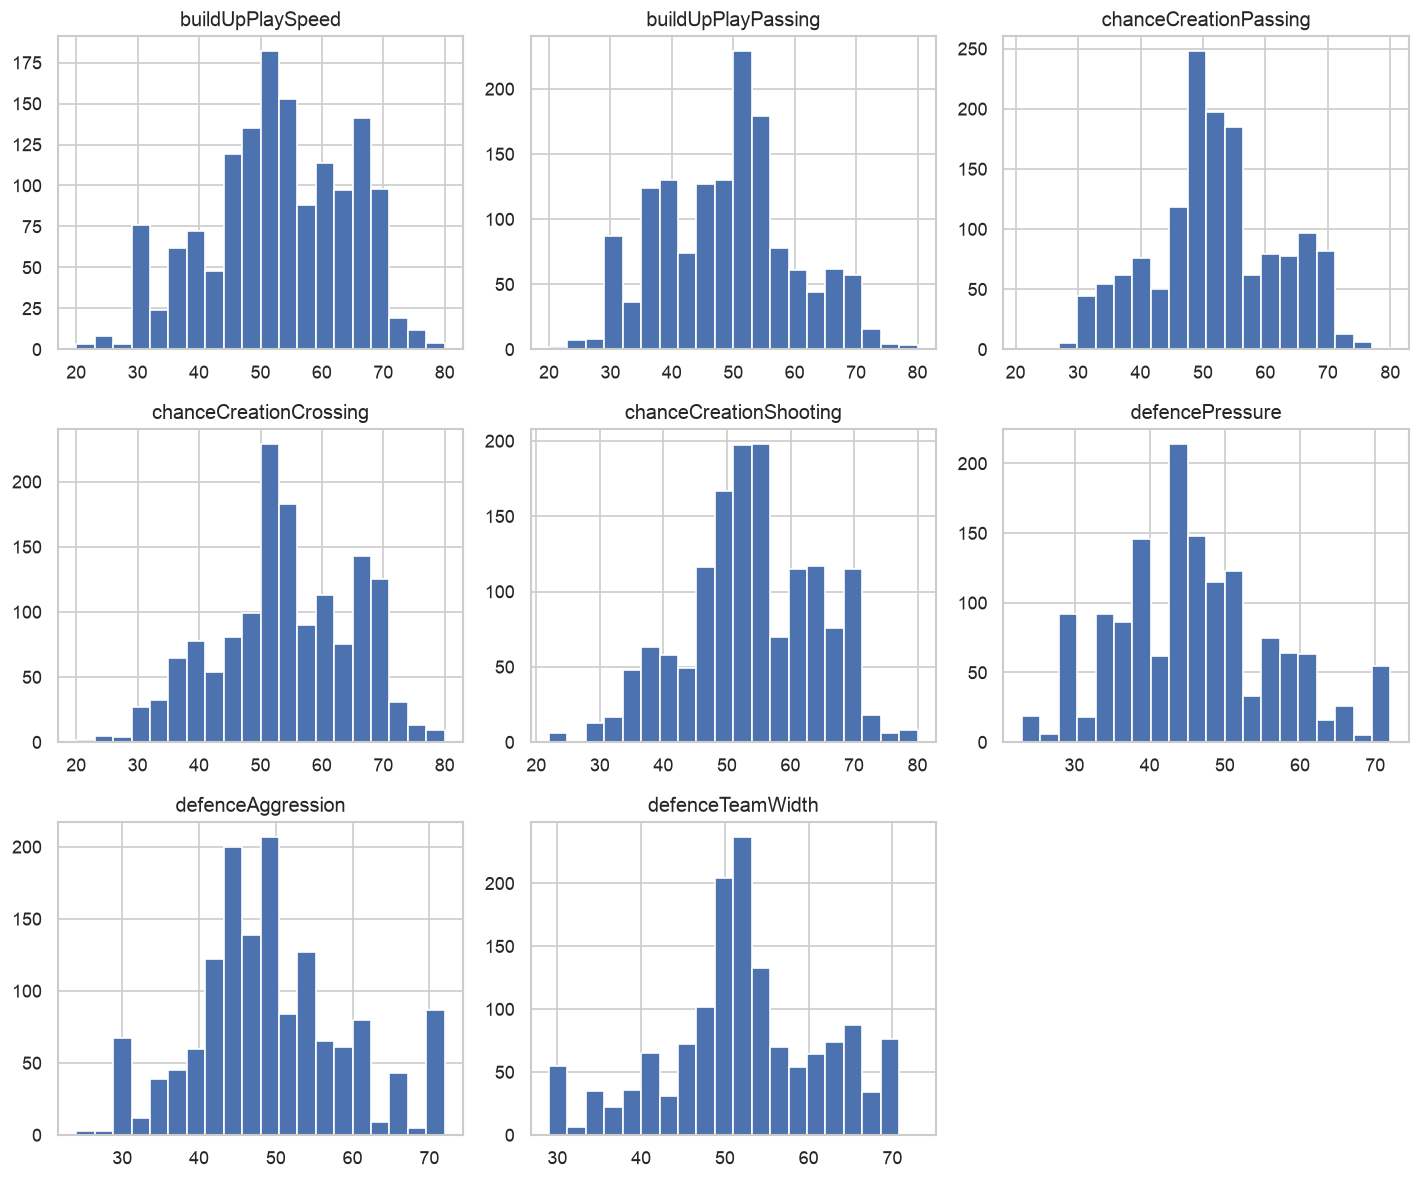

In [ ]:
team_attributes_df[tactical_features].hist(
    figsize=(12, 10),
    bins=20
)

plt.tight_layout()


plt.show()

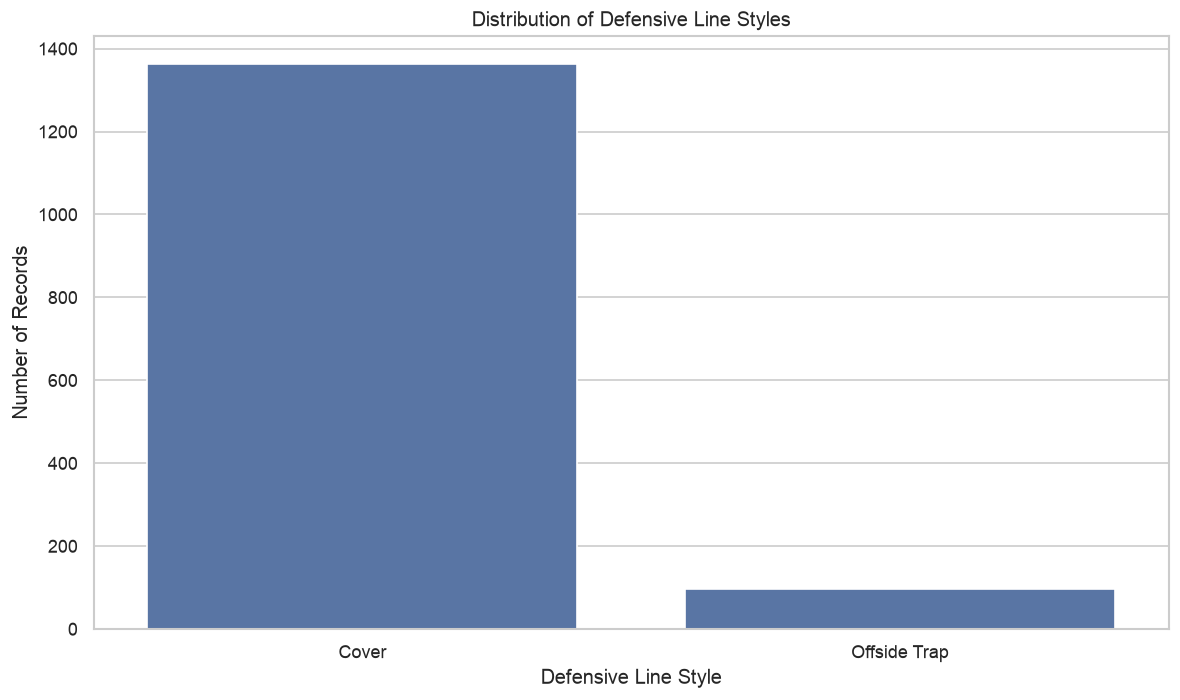

In [ ]:
sns.countplot(
    data=team_attributes_df,
    x="defenceDefenderLineClass"
)

plt.title("Distribution of Defensive Line Styles")
plt.xlabel("Defensive Line Style")
plt.ylabel("Number of Records")

plt.tight_layout()


plt.show()

In [93]:
correlation = team_attributes_df[
    tactical_features
].corr()

correlation

,buildUpPlaySpeed,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth
buildUpPlaySpeed,1.000000,0.395506,0.319162,0.191687,0.072098,0.046397,0.160569,0.067019
buildUpPlayPassing,0.395506,1.000000,0.220367,0.231088,-0.077325,-0.050487,0.122451,0.063150
chanceCreationPassing,0.319162,0.220367,1.000000,0.246528,0.112497,0.203158,0.145212,0.150143
chanceCreationCrossing,0.191687,0.231088,0.246528,1.000000,-0.012576,0.087108,0.098874,0.131515
chanceCreationShooting,0.072098,-0.077325,0.112497,-0.012576,1.000000,0.185603,0.116578,0.129166
defencePressure,0.046397,-0.050487,0.203158,0.087108,0.185603,1.000000,0.422493,0.508464
defenceAggression,0.160569,0.122451,0.145212,0.098874,0.116578,0.422493,1.000000,0.243189
defenceTeamWidth,0.067019,0.063150,0.150143,0.131515,0.129166,0.508464,0.243189,1.000000


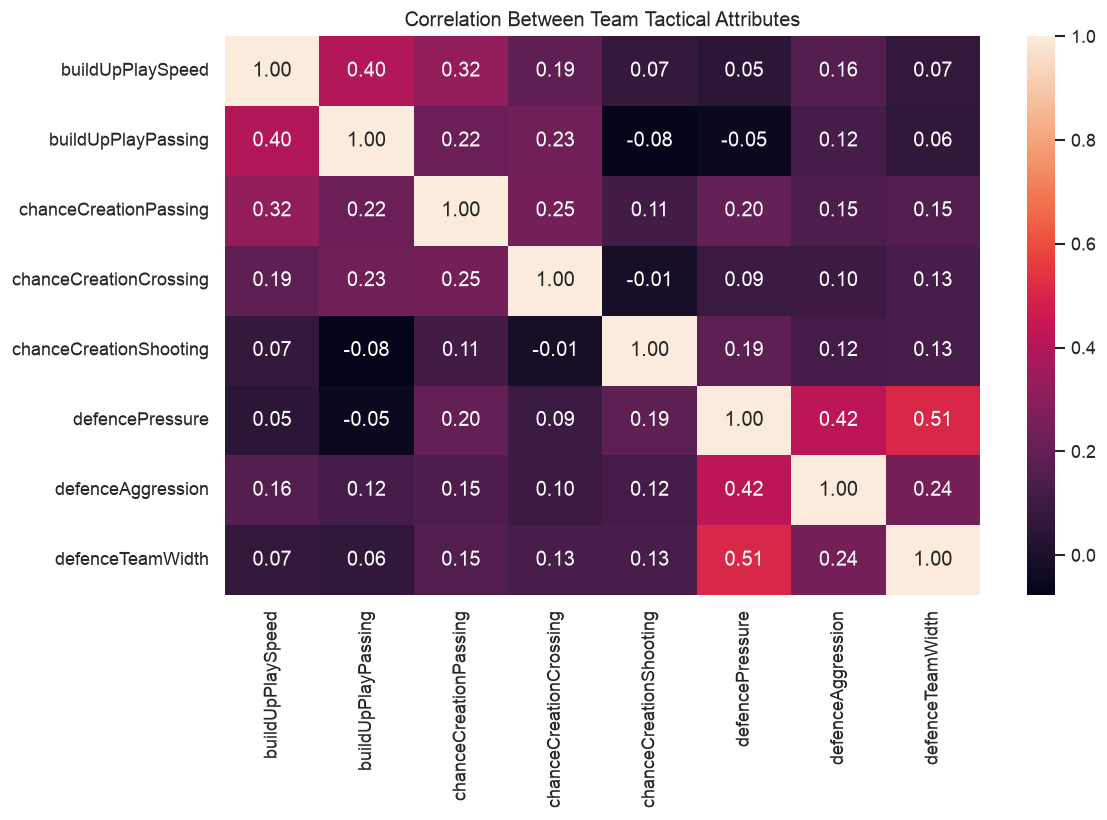

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Team Tactical Attributes")

plt.tight_layout()


plt.show()

In [95]:
team_attributes_named = team_attributes_df.merge(
    team_df[["team_api_id", "team_long_name"]],
    on="team_api_id",
    how="left"
)

In [96]:
team_attributes_named[
    ["team_long_name", "date", "buildUpPlaySpeed"]
].head()

,team_long_name,date,buildUpPlaySpeed
0,FC Aarau,2010-02-22,60
1,FC Aarau,2014-09-19,52
2,FC Aarau,2015-09-10,47
3,Aberdeen,2010-02-22,70
4,Aberdeen,2011-02-22,47


In [97]:
team_attributes_summary = (
    team_attributes_df[tactical_features]
    .describe()
)

team_attributes_summary.to_csv(
    "../outputs/tables/team_attributes_summary.csv"
)

In [98]:
team_attributes_df.isnull().sum().to_csv(
    "../outputs/tables/team_attributes_missing_values.csv"
)

### Team Attributes table EDA conclusion

- The Team_Attributes table contains historical tactical information for football teams.
- A team can appear multiple times because its attributes were recorded at different dates.
- Most tactical features are complete.
- `buildUpPlayDribbling` contains a large amount of missing data and was therefore not selected for the engineered dataset.
- Numerical features describe build-up play, chance creation and defensive behaviour.
- Categorical features describe tactical styles such as positioning and defensive line strategy.
- Tactical attributes vary between teams and over time.
- Correlations exist between some tactical variables and will be considered during later preprocessing and feature selection.
- The date of each attribute record is important because only information available before a match should be used for prediction.

### Player

In [99]:
player_df = pd.read_csv("../data/extracted/Player.csv")

player_df.head()

,id,player_api_id,player_name,player_fifa_api_id,birthday,height,weight
0,1,505942,Aaron Appindangoye,218353,1992-02-29 00:00:00,182.88,187
1,2,155782,Aaron Cresswell,189615,1989-12-15 00:00:00,170.18,146
2,3,162549,Aaron Doran,186170,1991-05-13 00:00:00,170.18,163
3,4,30572,Aaron Galindo,140161,1982-05-08 00:00:00,182.88,198
4,5,23780,Aaron Hughes,17725,1979-11-08 00:00:00,182.88,154


In [100]:
player_df.shape

(11060, 7)

In [101]:
player_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11060 entries, 0 to 11059
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  11060 non-null  int64  
 1   player_api_id       11060 non-null  int64  
 2   player_name         11060 non-null  str    
 3   player_fifa_api_id  11060 non-null  int64  
 4   birthday            11060 non-null  str    
 5   height              11060 non-null  float64
 6   weight              11060 non-null  int64  
dtypes: float64(1), int64(4), str(2)
memory usage: 605.0 KB


In [102]:
player_df.isnull().sum()


id                    0
player_api_id         0
player_name           0
player_fifa_api_id    0
birthday              0
height                0
weight                0
dtype: int64

In [103]:
player_df["player_api_id"].duplicated().sum()

np.int64(0)

In [104]:
player_df.duplicated().sum()

np.int64(0)

In [105]:
player_df["player_name"].duplicated().sum()

np.int64(212)

In [106]:
player_df[
    player_df["player_name"].duplicated(keep=False)
].sort_values("player_name")

,id,player_api_id,player_name,player_fifa_api_id,birthday,height,weight
84,85,26331,Adailton,158505,1983-04-14 00:00:00,190.50,187
85,86,41749,Adailton,4769,1977-01-24 00:00:00,175.26,161
98,99,23133,Adam Drury,101882,1978-08-29 00:00:00,180.34,161
99,100,420209,Adam Drury,205162,1993-09-09 00:00:00,177.80,152
137,138,181211,Adama Traore,193177,1990-02-03 00:00:00,170.18,161
...,...,...,...,...,...,...,...
11018,11034,185867,Ze Eduardo,181132,1987-10-29 00:00:00,177.80,185
11020,11036,25906,Ze Manuel,139083,1975-02-22 00:00:00,167.64,143
11021,11037,570159,Ze Manuel,223339,1990-10-23 00:00:00,177.80,157
11029,11045,175259,Zezinho,190228,1992-03-14 00:00:00,175.26,139


In [107]:
player_df["birthday"] = pd.to_datetime(
    player_df["birthday"]
)

In [108]:
print("Oldest birthday:", player_df["birthday"].min())
print("Youngest birthday:", player_df["birthday"].max())

Oldest birthday: 1967-01-23 00:00:00
Youngest birthday: 1999-04-24 00:00:00


In [109]:
player_df["height"].describe()

count    11060.000000
mean       181.867445
std          6.369201
min        157.480000
25%        177.800000
50%        182.880000
75%        185.420000
max        208.280000
Name: height, dtype: float64

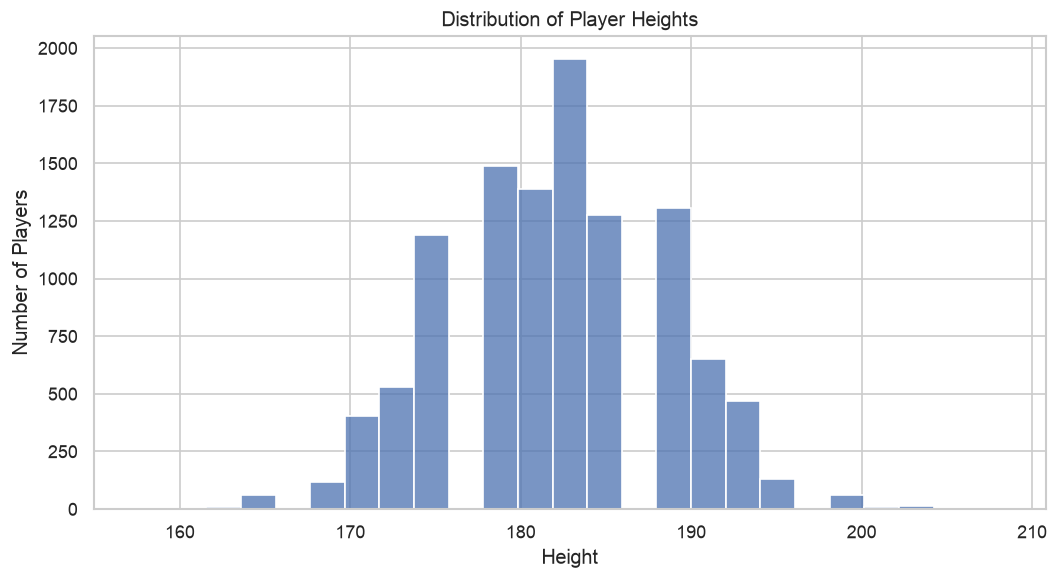

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    player_df["height"],
    bins=25
)

plt.title("Distribution of Player Heights")
plt.xlabel("Height")
plt.ylabel("Number of Players")

plt.tight_layout()

plt.show()

In [111]:
player_df["weight"].describe()

count    11060.000000
mean       168.380289
std         14.990217
min        117.000000
25%        159.000000
50%        168.000000
75%        179.000000
max        243.000000
Name: weight, dtype: float64

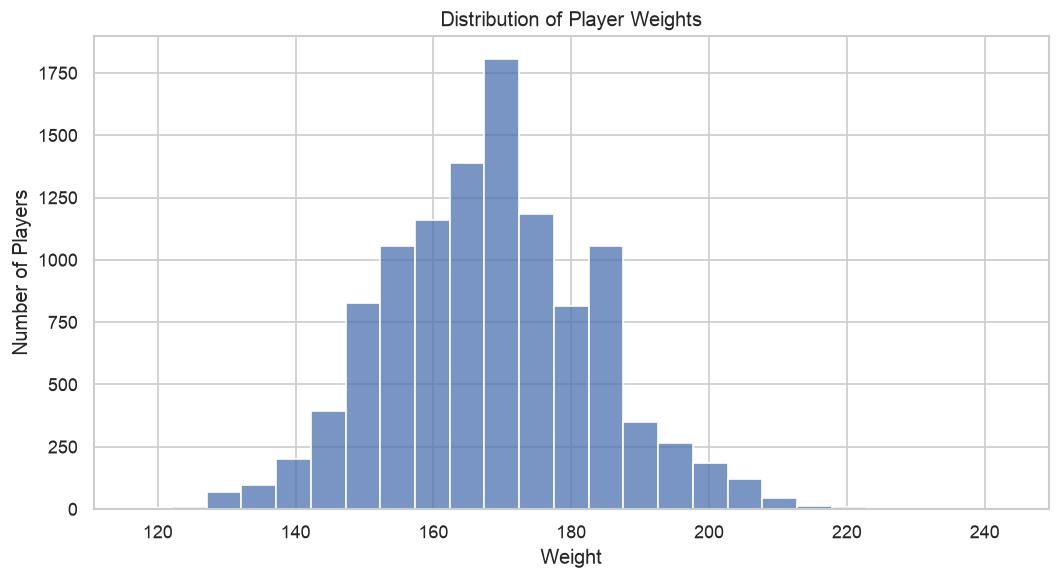

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    player_df["weight"],
    bins=25
)

plt.title("Distribution of Player Weights")
plt.xlabel("Weight")
plt.ylabel("Number of Players")

plt.tight_layout()


plt.show()

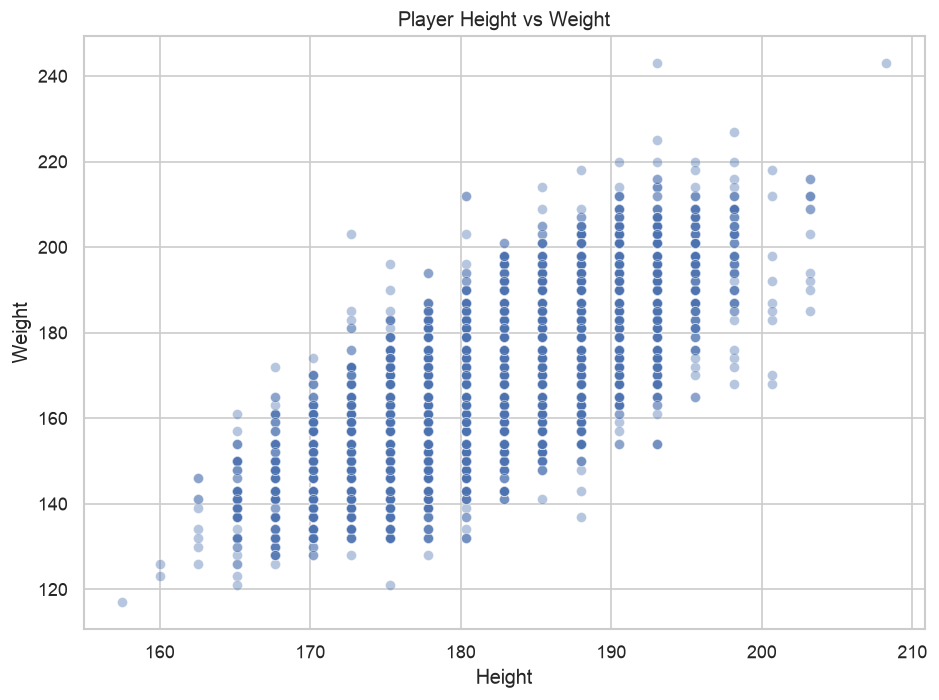

In [113]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=player_df,
    x="height",
    y="weight",
    alpha=0.4
)

plt.title("Player Height vs Weight")
plt.xlabel("Height")
plt.ylabel("Weight")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/player_height_vs_weight.png",
    dpi=300
)

plt.show()

In [114]:
player_summary = pd.DataFrame({
    "total_players": [len(player_df)],
    "missing_values": [
        player_df.isnull().sum().sum()
    ],
    "duplicate_player_ids": [
        player_df["player_api_id"].duplicated().sum()
    ],
    "average_height": [
        player_df["height"].mean()
    ],
    "average_weight": [
        player_df["weight"].mean()
    ]
})

player_summary

,total_players,missing_values,duplicate_player_ids,average_height,average_weight
0,11060,0,0,181.867445,168.380289


In [115]:
player_summary.to_csv(
    "../outputs/tables/player_summary.csv",
    index=False
)

### Player Attributes

In [116]:
player_attributes_df = pd.read_csv(
    "../data/extracted/Player_Attributes.csv"
)

player_attributes_df.head()

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
0,1,218353,505942,2016-02-18 00:00:00,67.0,71.0,right,medium,medium,49.0,...,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
1,2,218353,505942,2015-11-19 00:00:00,67.0,71.0,right,medium,medium,49.0,...,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
2,3,218353,505942,2015-09-21 00:00:00,62.0,66.0,right,medium,medium,49.0,...,54.0,48.0,65.0,66.0,69.0,6.0,11.0,10.0,8.0,8.0
3,4,218353,505942,2015-03-20 00:00:00,61.0,65.0,right,medium,medium,48.0,...,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0
4,5,218353,505942,2007-02-22 00:00:00,61.0,65.0,right,medium,medium,48.0,...,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0


In [117]:
player_attributes_df.shape

(183978, 42)

In [118]:
player_attributes_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 183978 entries, 0 to 183977
Data columns (total 42 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   id                   183978 non-null  int64  
 1   player_fifa_api_id   183978 non-null  int64  
 2   player_api_id        183978 non-null  int64  
 3   date                 183978 non-null  str    
 4   overall_rating       183142 non-null  float64
 5   potential            183142 non-null  float64
 6   preferred_foot       183142 non-null  str    
 7   attacking_work_rate  177109 non-null  str    
 8   defensive_work_rate  183142 non-null  str    
 9   crossing             183142 non-null  float64
 10  finishing            183142 non-null  float64
 11  heading_accuracy     183142 non-null  float64
 12  short_passing        183142 non-null  float64
 13  volleys              181265 non-null  float64
 14  dribbling            183142 non-null  float64
 15  curve                181265 

In [119]:
missing_player_attributes = (
    player_attributes_df.isnull().sum()
)

missing_player_attributes[
    missing_player_attributes > 0
].sort_values(ascending=False)

attacking_work_rate    6869
balance                2713
vision                 2713
agility                2713
sliding_tackle         2713
volleys                2713
jumping                2713
curve                  2713
strength                836
long_shots              836
aggression              836
interceptions           836
positioning             836
marking                 836
penalties               836
standing_tackle         836
gk_diving               836
gk_handling             836
gk_kicking              836
gk_positioning          836
stamina                 836
overall_rating          836
shot_power              836
potential               836
reactions               836
sprint_speed            836
acceleration            836
ball_control            836
long_passing            836
free_kick_accuracy      836
dribbling               836
short_passing           836
heading_accuracy        836
finishing               836
crossing                836
defensive_work_rate 

In [120]:
missing_percentage = (
    player_attributes_df.isnull().mean() * 100
)

missing_percentage[
    missing_percentage > 0
].sort_values(ascending=False)

attacking_work_rate    3.733599
balance                1.474633
vision                 1.474633
agility                1.474633
sliding_tackle         1.474633
volleys                1.474633
jumping                1.474633
curve                  1.474633
strength               0.454402
long_shots             0.454402
aggression             0.454402
interceptions          0.454402
positioning            0.454402
marking                0.454402
penalties              0.454402
standing_tackle        0.454402
gk_diving              0.454402
gk_handling            0.454402
gk_kicking             0.454402
gk_positioning         0.454402
stamina                0.454402
overall_rating         0.454402
shot_power             0.454402
potential              0.454402
reactions              0.454402
sprint_speed           0.454402
acceleration           0.454402
ball_control           0.454402
long_passing           0.454402
free_kick_accuracy     0.454402
dribbling              0.454402
short_pa

In [121]:
player_attributes_df.duplicated().sum()

np.int64(0)

In [122]:
player_attributes_df["id"].duplicated().sum()

np.int64(0)

In [123]:
player_attributes_df["date"] = pd.to_datetime(
    player_attributes_df["date"]
)

In [124]:
print(
    "First record:",
    player_attributes_df["date"].min()
)

print(
    "Last record:",
    player_attributes_df["date"].max()
)

First record: 2007-02-22 00:00:00
Last record: 2016-07-07 00:00:00


In [125]:
player_attributes_df[
    "player_api_id"
].nunique()

11060

In [126]:
player_df[
    "player_api_id"
].nunique()

11060

In [127]:
player_attributes_df[
    "player_api_id"
].value_counts().describe()

count    11060.000000
mean        16.634539
std          9.395639
min          2.000000
25%          8.000000
50%         16.000000
75%         23.000000
max         56.000000
Name: count, dtype: float64

In [128]:
player_attributes_df[
    "overall_rating"
].describe()

count    183142.000000
mean         68.600015
std           7.041139
min          33.000000
25%          64.000000
50%          69.000000
75%          73.000000
max          94.000000
Name: overall_rating, dtype: float64

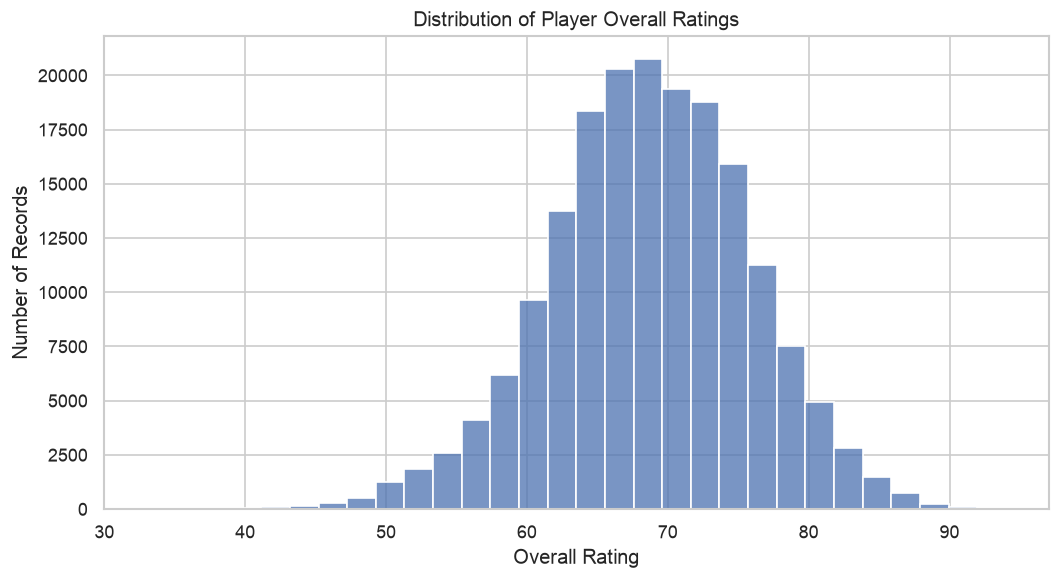

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    player_attributes_df["overall_rating"],
    bins=30
)

plt.title("Distribution of Player Overall Ratings")
plt.xlabel("Overall Rating")
plt.ylabel("Number of Records")

plt.tight_layout()

plt.show()

In [130]:
player_attributes_df[
    "potential"
].describe()

count    183142.000000
mean         73.460353
std           6.592271
min          39.000000
25%          69.000000
50%          74.000000
75%          78.000000
max          97.000000
Name: potential, dtype: float64

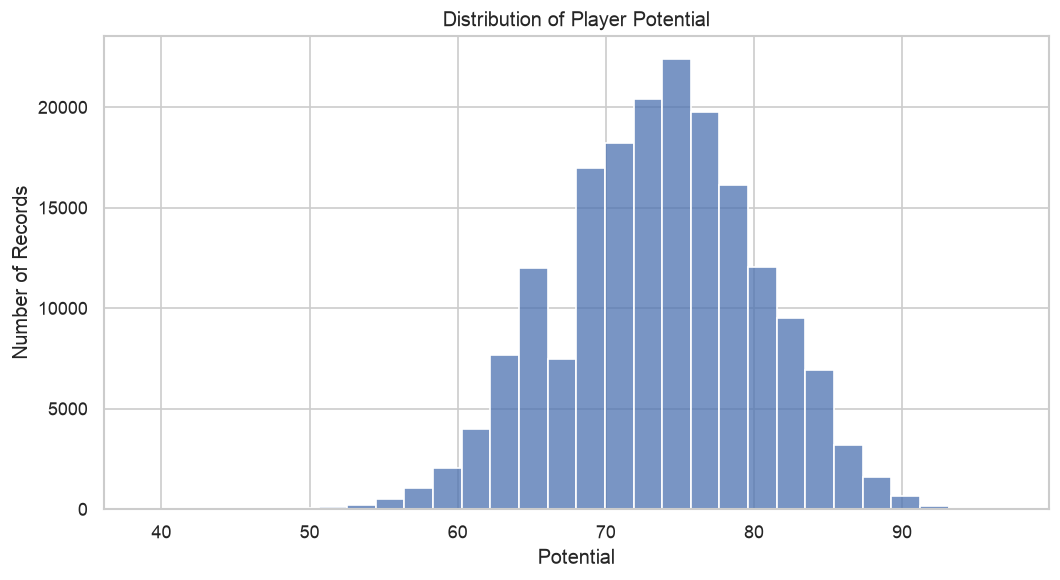

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    player_attributes_df["potential"],
    bins=30
)

plt.title("Distribution of Player Potential")
plt.xlabel("Potential")
plt.ylabel("Number of Records")

plt.tight_layout()


plt.show()


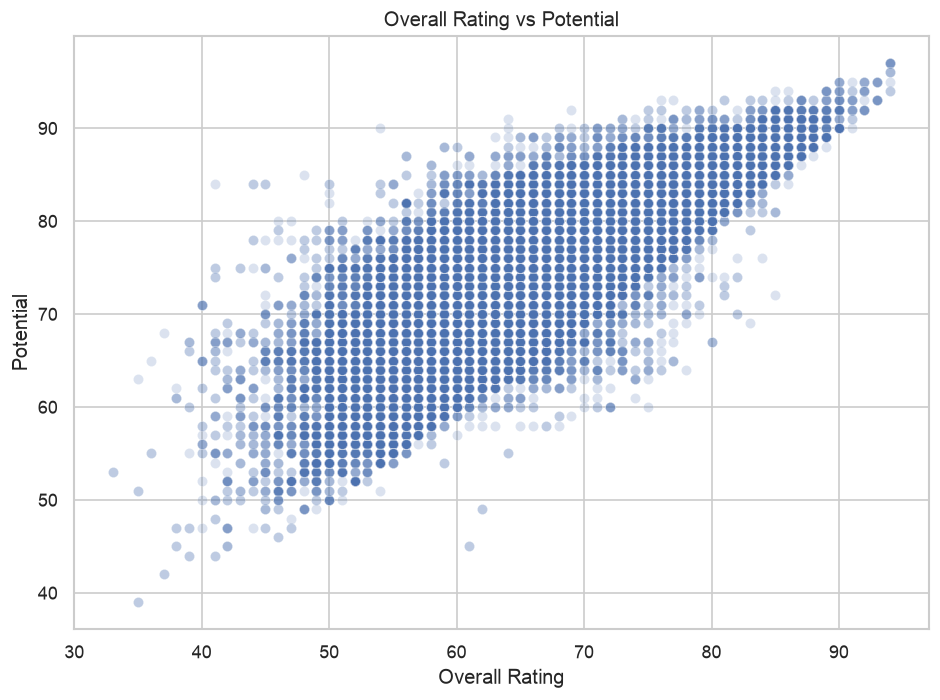

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=player_attributes_df,
    x="overall_rating",
    y="potential",
    alpha=0.2
)

plt.title("Overall Rating vs Potential")
plt.xlabel("Overall Rating")
plt.ylabel("Potential")

plt.tight_layout()


plt.show()

In [133]:
player_attributes_df[
    "preferred_foot"
].value_counts()

preferred_foot
right    138409
left      44733
Name: count, dtype: int64

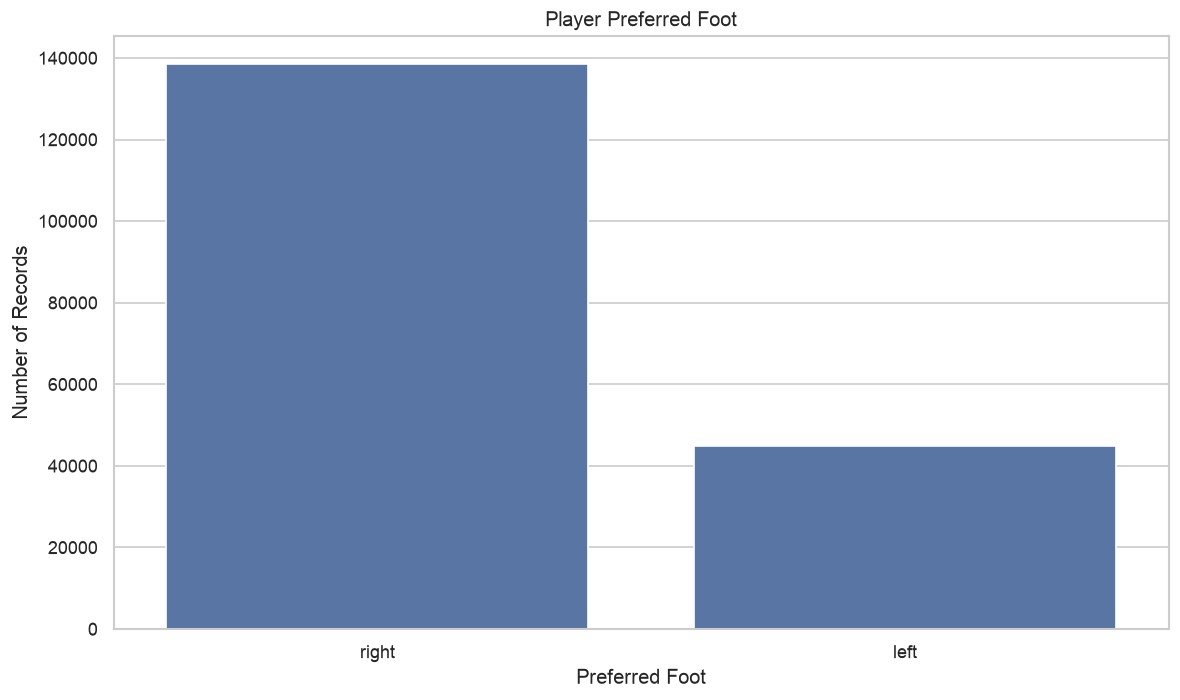

In [134]:
sns.countplot(
    data=player_attributes_df,
    x="preferred_foot"
)

plt.title("Player Preferred Foot")
plt.xlabel("Preferred Foot")
plt.ylabel("Number of Records")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/player_preferred_foot.png",
    dpi=300
)

plt.show()

In [135]:
player_attributes_df[
    "attacking_work_rate"
].value_counts(dropna=False)

attacking_work_rate
medium    125070
high       42823
low         8569
NaN         6869
norm         348
y            106
le           104
stoc          89
Name: count, dtype: int64

In [136]:
player_attributes_df[
    "defensive_work_rate"
].value_counts(dropna=False)

defensive_work_rate
medium    130846
high       27041
low        18432
_0          2394
o           1550
NaN          836
1            441
ormal        348
2            342
3            258
5            234
7            217
0            197
6            197
9            152
4            116
es           106
ean          104
tocky         89
8             78
Name: count, dtype: int64

In [137]:
important_player_features = [
    "overall_rating",
    "potential",
    "finishing",
    "short_passing",
    "dribbling",
    "acceleration",
    "sprint_speed",
    "strength",
    "interceptions",
    "standing_tackle",
    "gk_reflexes"
]

In [138]:
player_attributes_df[
    important_player_features
].describe()

,overall_rating,potential,finishing,short_passing,dribbling,acceleration,sprint_speed,strength,interceptions,standing_tackle,gk_reflexes
count,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000
mean,68.600015,73.460353,49.921078,62.429672,59.175154,67.659357,68.051244,67.424529,52.009271,50.351257,16.441439
std,7.041139,6.592271,19.038705,14.194068,17.744688,12.983326,12.569721,12.072280,19.450133,21.483706,17.198155
min,33.000000,39.000000,1.000000,3.000000,1.000000,10.000000,12.000000,10.000000,1.000000,1.000000,1.000000
25%,64.000000,69.000000,34.000000,57.000000,52.000000,61.000000,62.000000,60.000000,34.000000,29.000000,8.000000
50%,69.000000,74.000000,53.000000,65.000000,64.000000,69.000000,69.000000,69.000000,57.000000,56.000000,11.000000
75%,73.000000,78.000000,65.000000,72.000000,72.000000,77.000000,77.000000,76.000000,68.000000,69.000000,15.000000
max,94.000000,97.000000,97.000000,97.000000,97.000000,97.000000,97.000000,96.000000,96.000000,95.000000,96.000000


In [139]:
correlation = player_attributes_df[
    important_player_features
].corr()

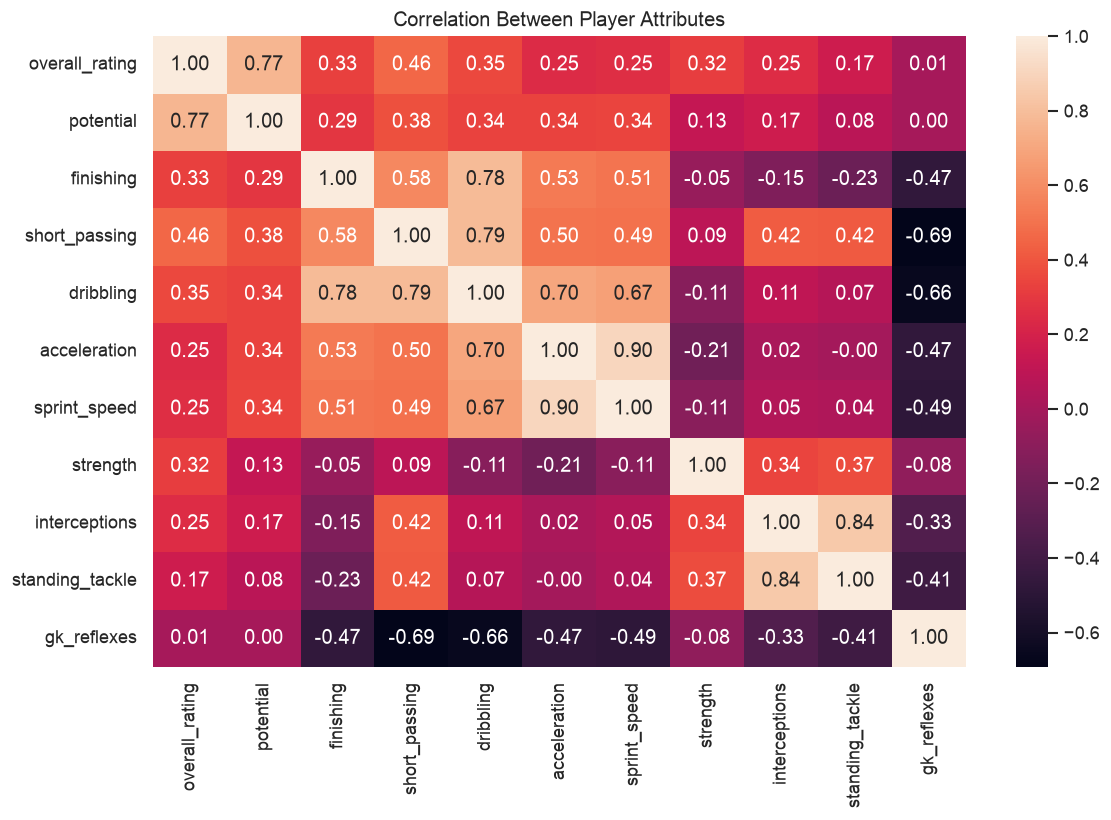

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Player Attributes")

plt.tight_layout()


plt.show()

In [141]:
player_attributes_df["year"] = (
    player_attributes_df["date"].dt.year
)

In [142]:
rating_by_year = (
    player_attributes_df.groupby("year")
    ["overall_rating"]
    .mean()
)

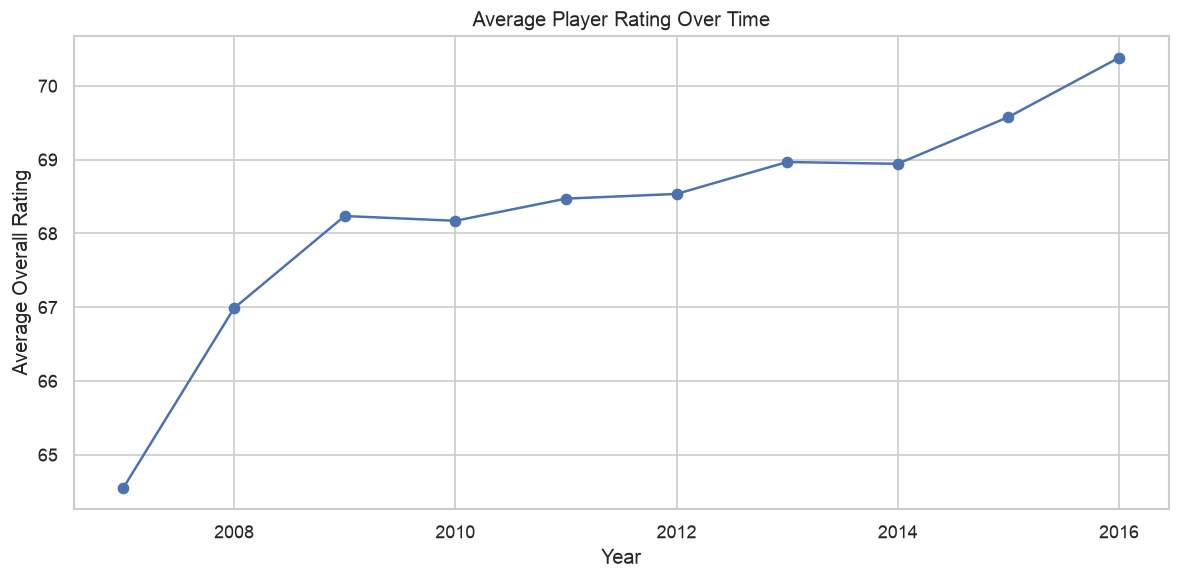

In [143]:
rating_by_year.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Average Player Rating Over Time")
plt.xlabel("Year")
plt.ylabel("Average Overall Rating")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/player_rating_over_time.png",
    dpi=300
)

plt.show()

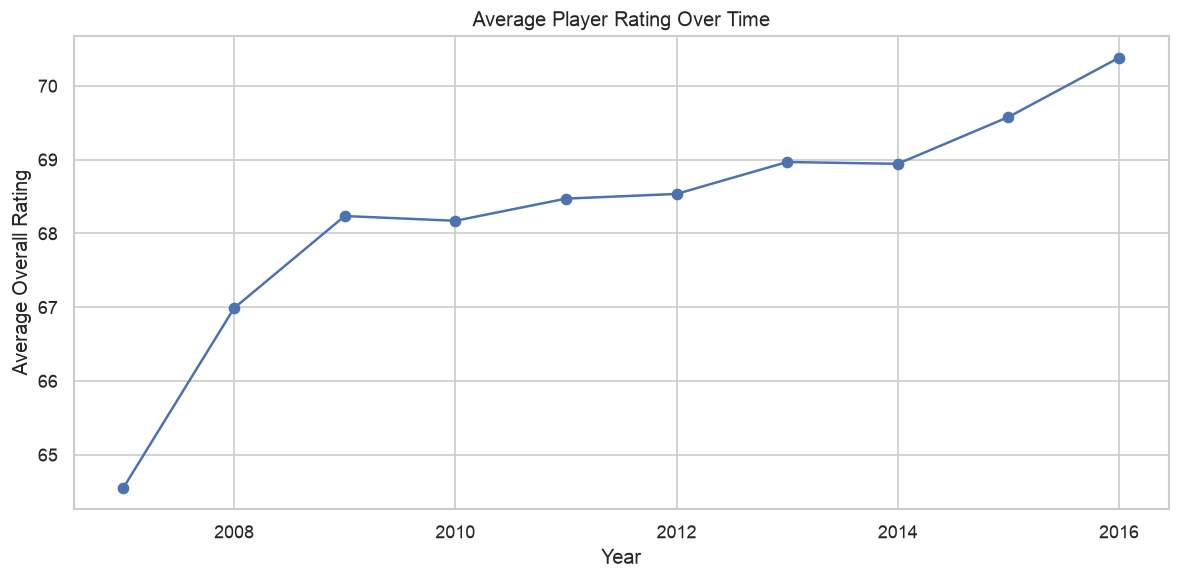

In [144]:
rating_by_year.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Average Player Rating Over Time")
plt.xlabel("Year")
plt.ylabel("Average Overall Rating")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/player_rating_over_time.png",
    dpi=300
)

plt.show()

In [145]:
missing_percentage.to_csv(
    "../outputs/tables/player_attributes_missing_values.csv"
)

In [146]:
player_attributes_df[
    important_player_features
].describe().to_csv(
    "../outputs/tables/player_attributes_summary.csv"
)

### League

In [147]:
league_df = pd.read_csv("../data/extracted/League.csv")

league_df

,id,country_id,name
0,1,1,Belgium Jupiler League
1,1729,1729,England Premier League
2,4769,4769,France Ligue 1
3,7809,7809,Germany 1. Bundesliga
4,10257,10257,Italy Serie A
5,13274,13274,Netherlands Eredivisie
6,15722,15722,Poland Ekstraklasa
7,17642,17642,Portugal Liga ZON Sagres
8,19694,19694,Scotland Premier League
9,21518,21518,Spain LIGA BBVA


In [148]:
league_df.shape

(11, 3)

In [149]:
league_df.isnull().sum()

id            0
country_id    0
name          0
dtype: int64

In [150]:
league_df["id"].duplicated().sum()

np.int64(0)

In [151]:
league_df["name"].duplicated().sum()

np.int64(0)

In [152]:
league_df[["id", "name"]]

,id,name
0,1,Belgium Jupiler League
1,1729,England Premier League
2,4769,France Ligue 1
3,7809,Germany 1. Bundesliga
4,10257,Italy Serie A
5,13274,Netherlands Eredivisie
6,15722,Poland Ekstraklasa
7,17642,Portugal Liga ZON Sagres
8,19694,Scotland Premier League
9,21518,Spain LIGA BBVA


In [155]:
league_df["country_id"].isin(
    country_df["id"]
).value_counts()

country_id
True    11
Name: count, dtype: int64

### Country

In [154]:
country_df = pd.read_csv("../data/extracted/Country.csv")

country_df

,id,name
0,1,Belgium
1,1729,England
2,4769,France
3,7809,Germany
4,10257,Italy
5,13274,Netherlands
6,15722,Poland
7,17642,Portugal
8,19694,Scotland
9,21518,Spain


In [156]:
country_df.shape

(11, 2)

In [157]:
country_df.isnull().sum()

id      0
name    0
dtype: int64

In [158]:
country_df["id"].duplicated().sum()

np.int64(0)

In [159]:
country_df["name"].duplicated().sum()

np.int64(0)

In [160]:
country_df

,id,name
0,1,Belgium
1,1729,England
2,4769,France
3,7809,Germany
4,10257,Italy
5,13274,Netherlands
6,15722,Poland
7,17642,Portugal
8,19694,Scotland
9,21518,Spain


In [161]:
league_country = league_df.merge(
    country_df,
    left_on="country_id",
    right_on="id"
)

In [162]:
league_country[
    ["name_x", "name_y"]
]

,name_x,name_y
0,Belgium Jupiler League,Belgium
1,England Premier League,England
2,France Ligue 1,France
3,Germany 1. Bundesliga,Germany
4,Italy Serie A,Italy
5,Netherlands Eredivisie,Netherlands
6,Poland Ekstraklasa,Poland
7,Portugal Liga ZON Sagres,Portugal
8,Scotland Premier League,Scotland
9,Spain LIGA BBVA,Spain


### League and Country tables EDA conclusion

- The Country table contains 11 countries.
- The League table contains 11 football leagues.
- Both tables are small lookup/reference tables with complete records.
- Each league contains a `country_id` that connects it to the Country table.
- League information is connected to matches using `league_id`.
- These tables mainly provide contextual information rather than detailed performance measurements.
- Country and league names help make the match dataset easier to interpret.
- Raw numerical IDs should not automatically be treated as continuous machine learning features.